# Can Machine Learning Beat the Stock Market?

Project 2 · Random Forest and XGBoost · January 2015–December 2025

**Reproducible, self-contained submission.** All source code and the real historical data snapshot are contained in this notebook. Running it creates its working files; no separate source files or Drive permissions are required. SPY is a benchmark only. The optional frontend is a historical prediction replay and a $100,000 simulated account.

The additional 70% prediction goal has no agreed metric. This notebook reports the assignment metrics without inventing an accuracy measure. Models and parameters are selected before inspecting final test results.

## Contents

1. Data Collection and Exploratory Analysis
2. Feature Engineering
3. Prediction Targets
4. Machine Learning Model Development
5. Portfolio Simulation
6. Model Interpretation and Scientific Discussion

Final Deliverable: reproducibility, sources and AI assistance.

## 1. Data Collection and Exploratory Analysis

### 1.1 Environment, data acquisition and snapshot

The original dataset was downloaded with yfinance using start=2015-01-01 and the exclusive end=2026-01-01. A compressed snapshot is embedded below for reproducibility. It contains no 2026 observations. Optional refreshing is disabled by default because adjusted historical prices may be revised. Python 3.12 was used for verification.

In [1]:
import importlib.util, subprocess, sys
packages={"numpy":"numpy==2.5.4","pandas":"pandas==2.3.3","matplotlib":"matplotlib==3.11.2","sklearn":"scikit-learn==1.9.1","xgboost":"xgboost==3.4.1","scipy":"scipy==1.18.1","joblib":"joblib==1.6.0","yfinance":"yfinance==0.2.66"}
missing=[requirement for module,requirement in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])
import numpy as np
np.random.seed(42)

In [2]:
import base64, os, sys
from pathlib import Path
PROJECT=Path.cwd()/"stock_market_generated"
PROJECT.mkdir(exist_ok=True)
CODE=Path.cwd()/"_stock_market_code"
CODE.mkdir(exist_ok=True)
sys.path.insert(0,str(CODE))
os.environ["STOCK_PROJECT"]=str(PROJECT)
os.environ["MPLCONFIGDIR"]=str(PROJECT/".mpl_cache")
SNAPSHOTS={'events.csv': 'ZGF0ZSxjYXRlZ29yeSxuYW1lLHNvdXJjZSxhdmFpbGFiaWxpdHlfcnVsZQ0KMjAxOC0wNi0xNSx0YXJpZmYsQ2hpbmEgdGFyaWZmIGFubm91bmNlbWVudCxodHRwczovL3VzdHIuZ292L2Fib3V0LXVzL3BvbGljeS1vZmZpY2VzL3ByZXNzLW9mZmljZS9wcmVzcy1yZWxlYXNlcy8yMDE4L2p1bmUvdXN0ci1pc3N1ZXMtdGFyaWZmcy1jaGluZXNlLXByb2R1Y3RzLE5leHQgdHJhZGluZyBzZXNzaW9uIGFmdGVyIHB1YmxpY2F0aW9uIGRhdGU7IG5vIGVzdGltYXRlZCBtYXJrZXQgZWZmZWN0DQoyMDE4LTA3LTA2LHRhcmlmZixDaGluYSB0YXJpZmYgaW1wbGVtZW50YXRpb24saHR0cHM6Ly91c3RyLmdvdi9hYm91dC11cy9wb2xpY3ktb2ZmaWNlcy9wcmVzcy1vZmZpY2UvcHJlc3MtcmVsZWFzZXMvMjAxOC9qdWx5L3VzdHItcmVsZWFzZXMtcHJvZHVjdC1leGNsdXNpb24sTmV4dCB0cmFkaW5nIHNlc3Npb24gYWZ0ZXIgcHVibGljYXRpb24gZGF0ZTsgbm8gZXN0aW1hdGVkIG1hcmtldCBlZmZlY3QNCjIwMjAtMDEtMzAsaGVhbHRoLFdITyBwdWJsaWMgaGVhbHRoIGVtZXJnZW5jeSxodHRwczovL3d3dy53aG8uaW50L25ld3MvaXRlbS8yOS0wNi0yMDIwLUNPVklEdGltZWxpbmUsTmV4dCB0cmFkaW5nIHNlc3Npb24gYWZ0ZXIgcHVibGljYXRpb24gZGF0ZTsgbm8gZXN0aW1hdGVkIG1hcmtldCBlZmZlY3QNCjIwMjAtMDMtMTEsaGVhbHRoLFdITyBwYW5kZW1pYyBkZWNsYXJhdGlvbixodHRwczovL3d3dy53aG8uaW50L25ld3MvaXRlbS8yOS0wNi0yMDIwLUNPVklEdGltZWxpbmUsTmV4dCB0cmFkaW5nIHNlc3Npb24gYWZ0ZXIgcHVibGljYXRpb24gZGF0ZTsgbm8gZXN0aW1hdGVkIG1hcmtldCBlZmZlY3QNCjIwMjItMDItMjQsd2FyLFJ1c3NpYW4gaW52YXNpb24gb2YgVWtyYWluZSxodHRwczovL3d3dy5jb25zaWxpdW0uZXVyb3BhLmV1L2VuL21lZXRpbmdzL2V1cm9wZWFuLWNvdW5jaWwvMjAyMi8wMi8yNC8sTmV4dCB0cmFkaW5nIHNlc3Npb24gYWZ0ZXIgcHVibGljYXRpb24gZGF0ZTsgbm8gZXN0aW1hdGVkIG1hcmtldCBlZmZlY3QNCjIwMjUtMDQtMDIsdGFyaWZmLFJlY2lwcm9jYWwgdGFyaWZmIGFubm91bmNlbWVudCxodHRwczovL3d3dy53aGl0ZWhvdXNlLmdvdi9wcmVzaWRlbnRpYWwtYWN0aW9ucy8yMDI1LzA0L3JlZ3VsYXRpbmctaW1wb3J0cy13aXRoLWEtcmVjaXByb2NhbC10YXJpZmYtdG8tcmVjdGlmeS10cmFkZS1wcmFjdGljZXMtdGhhdC1jb250cmlidXRlLXRvLWxhcmdlLWFuZC1wZXJzaXN0ZW50LWFubnVhbC11bml0ZWQtc3RhdGVzLWdvb2RzLXRyYWRlLWRlZmljaXRzLyxOZXh0IHRyYWRpbmcgc2Vzc2lvbiBhZnRlciBwdWJsaWNhdGlvbiBkYXRlOyBubyBlc3RpbWF0ZWQgbWFya2V0IGVmZmVjdA0K', 'fed_policy.csv': 'ZGF0ZSxyYXRlX3VwcGVyLGNoYW5nZV9icHMsc291cmNlLGF2YWlsYWJpbGl0eV9ydWxlDQoyMDE0LTEyLTMxLDAuMjUsMC4wLGh0dHBzOi8vd3d3LmZlZGVyYWxyZXNlcnZlLmdvdi9tb25ldGFyeXBvbGljeS9vcGVubWFya2V0Lmh0bSxOZXh0IHRyYWRpbmcgc2Vzc2lvbiBhZnRlciBsaXN0ZWQgcG9saWN5IGRhdGU7IGNvbnNlcnZhdGl2ZSBsYWcNCjIwMTUtMTItMTcsMC41LDI1LjAsaHR0cHM6Ly93d3cuZmVkZXJhbHJlc2VydmUuZ292L21vbmV0YXJ5cG9saWN5L29wZW5tYXJrZXQuaHRtLE5leHQgdHJhZGluZyBzZXNzaW9uIGFmdGVyIGxpc3RlZCBwb2xpY3kgZGF0ZTsgY29uc2VydmF0aXZlIGxhZw0KMjAxNi0xMi0xNSwwLjc1LDI1LjAsaHR0cHM6Ly93d3cuZmVkZXJhbHJlc2VydmUuZ292L21vbmV0YXJ5cG9saWN5L29wZW5tYXJrZXQuaHRtLE5leHQgdHJhZGluZyBzZXNzaW9uIGFmdGVyIGxpc3RlZCBwb2xpY3kgZGF0ZTsgY29uc2VydmF0aXZlIGxhZw0KMjAxNy0wMy0xNiwxLjAsMjUuMCxodHRwczovL3d3dy5mZWRlcmFscmVzZXJ2ZS5nb3YvbW9uZXRhcnlwb2xpY3kvb3Blbm1hcmtldC5odG0sTmV4dCB0cmFkaW5nIHNlc3Npb24gYWZ0ZXIgbGlzdGVkIHBvbGljeSBkYXRlOyBjb25zZXJ2YXRpdmUgbGFnDQoyMDE3LTA2LTE1LDEuMjUsMjUuMCxodHRwczovL3d3dy5mZWRlcmFscmVzZXJ2ZS5nb3YvbW9uZXRhcnlwb2xpY3kvb3Blbm1hcmtldC5odG0sTmV4dCB0cmFkaW5nIHNlc3Npb24gYWZ0ZXIgbGlzdGVkIHBvbGljeSBkYXRlOyBjb25zZXJ2YXRpdmUgbGFnDQoyMDE3LTEyLTE0LDEuNSwyNS4wLGh0dHBzOi8vd3d3LmZlZGVyYWxyZXNlcnZlLmdvdi9tb25ldGFyeXBvbGljeS9vcGVubWFya2V0Lmh0bSxOZXh0IHRyYWRpbmcgc2Vzc2lvbiBhZnRlciBsaXN0ZWQgcG9saWN5IGRhdGU7IGNvbnNlcnZhdGl2ZSBsYWcNCjIwMTgtMDMtMjIsMS43NSwyNS4wLGh0dHBzOi8vd3d3LmZlZGVyYWxyZXNlcnZlLmdvdi9tb25ldGFyeXBvbGljeS9vcGVubWFya2V0Lmh0bSxOZXh0IHRyYWRpbmcgc2Vzc2lvbiBhZnRlciBsaXN0ZWQgcG9saWN5IGRhdGU7IGNvbnNlcnZhdGl2ZSBsYWcNCjIwMTgtMDYtMTQsMi4wLDI1LjAsaHR0cHM6Ly93d3cuZmVkZXJhbHJlc2VydmUuZ292L21vbmV0YXJ5cG9saWN5L29wZW5tYXJrZXQuaHRtLE5leHQgdHJhZGluZyBzZXNzaW9uIGFmdGVyIGxpc3RlZCBwb2xpY3kgZGF0ZTsgY29uc2VydmF0aXZlIGxhZw0KMjAxOC0wOS0yNywyLjI1LDI1LjAsaHR0cHM6Ly93d3cuZmVkZXJhbHJlc2VydmUuZ292L21vbmV0YXJ5cG9saWN5L29wZW5tYXJrZXQuaHRtLE5leHQgdHJhZGluZyBzZXNzaW9uIGFmdGVyIGxpc3RlZCBwb2xpY3kgZGF0ZTsgY29uc2VydmF0aXZlIGxhZw0KMjAxOC0xMi0yMCwyLjUsMjUuMCxodHRwczovL3d3dy5mZWRlcmFscmVzZXJ2ZS5nb3YvbW9uZXRhcnlwb2xpY3kvb3Blbm1hcmtldC5odG0sTmV4dCB0cmFkaW5nIHNlc3Npb24gYWZ0ZXIgbGlzdGVkIHBvbGljeSBkYXRlOyBjb25zZXJ2YXRpdmUgbGFnDQoyMDE5LTA4LTAxLDIuMjUsLTI1LjAsaHR0cHM6Ly93d3cuZmVkZXJhbHJlc2VydmUuZ292L21vbmV0YXJ5cG9saWN5L29wZW5tYXJrZXQuaHRtLE5leHQgdHJhZGluZyBzZXNzaW9uIGFmdGVyIGxpc3RlZCBwb2xpY3kgZGF0ZTsgY29uc2VydmF0aXZlIGxhZw0KMjAxOS0wOS0xOSwyLjAsLTI1LjAsaHR0cHM6Ly93d3cuZmVkZXJhbHJlc2VydmUuZ292L21vbmV0YXJ5cG9saWN5L29wZW5tYXJrZXQuaHRtLE5leHQgdHJhZGluZyBzZXNzaW9uIGFmdGVyIGxpc3RlZCBwb2xpY3kgZGF0ZTsgY29uc2VydmF0aXZlIGxhZw0KMjAxOS0xMC0zMSwxLjc1LC0yNS4wLGh0dHBzOi8vd3d3LmZlZGVyYWxyZXNlcnZlLmdvdi9tb25ldGFyeXBvbGljeS9vcGVubWFya2V0Lmh0bSxOZXh0IHRyYWRpbmcgc2Vzc2lvbiBhZnRlciBsaXN0ZWQgcG9saWN5IGRhdGU7IGNvbnNlcnZhdGl2ZSBsYWcNCjIwMjAtMDMtMDQsMS4yNSwtNTAuMCxodHRwczovL3d3dy5mZWRlcmFscmVzZXJ2ZS5nb3YvbW9uZXRhcnlwb2xpY3kvb3Blbm1hcmtldC5odG0sTmV4dCB0cmFkaW5nIHNlc3Npb24gYWZ0ZXIgbGlzdGVkIHBvbGljeSBkYXRlOyBjb25zZXJ2YXRpdmUgbGFnDQoyMDIwLTAzLTE2LDAuMjUsLTEwMC4wLGh0dHBzOi8vd3d3LmZlZGVyYWxyZXNlcnZlLmdvdi9tb25ldGFyeXBvbGljeS9vcGVubWFya2V0Lmh0bSxOZXh0IHRyYWRpbmcgc2Vzc2lvbiBhZnRlciBsaXN0ZWQgcG9saWN5IGRhdGU7IGNvbnNlcnZhdGl2ZSBsYWcNCjIwMjItMDMtMTcsMC41LDI1LjAsaHR0cHM6Ly93d3cuZmVkZXJhbHJlc2VydmUuZ292L21vbmV0YXJ5cG9saWN5L29wZW5tYXJrZXQuaHRtLE5leHQgdHJhZGluZyBzZXNzaW9uIGFmdGVyIGxpc3RlZCBwb2xpY3kgZGF0ZTsgY29uc2VydmF0aXZlIGxhZw0KMjAyMi0wNS0wNSwxLjAsNTAuMCxodHRwczovL3d3dy5mZWRlcmFscmVzZXJ2ZS5nb3YvbW9uZXRhcnlwb2xpY3kvb3Blbm1hcmtldC5odG0sTmV4dCB0cmFkaW5nIHNlc3Npb24gYWZ0ZXIgbGlzdGVkIHBvbGljeSBkYXRlOyBjb25zZXJ2YXRpdmUgbGFnDQoyMDIyLTA2LTE2LDEuNzUsNzUuMCxodHRwczovL3d3dy5mZWRlcmFscmVzZXJ2ZS5nb3YvbW9uZXRhcnlwb2xpY3kvb3Blbm1hcmtldC5odG0sTmV4dCB0cmFkaW5nIHNlc3Npb24gYWZ0ZXIgbGlzdGVkIHBvbGljeSBkYXRlOyBjb25zZXJ2YXRpdmUgbGFnDQoyMDIyLTA3LTI4LDIuNSw3NS4wLGh0dHBzOi8vd3d3LmZlZGVyYWxyZXNlcnZlLmdvdi9tb25ldGFyeXBvbGljeS9vcGVubWFya2V0Lmh0bSxOZXh0IHRyYWRpbmcgc2Vzc2lvbiBhZnRlciBsaXN0ZWQgcG9saWN5IGRhdGU7IGNvbnNlcnZhdGl2ZSBsYWcNCjIwMjItMDktMjIsMy4yNSw3NS4wLGh0dHBzOi8vd3d3LmZlZGVyYWxyZXNlcnZlLmdvdi9tb25ldGFyeXBvbGljeS9vcGVubWFya2V0Lmh0bSxOZXh0IHRyYWRpbmcgc2Vzc2lvbiBhZnRlciBsaXN0ZWQgcG9saWN5IGRhdGU7IGNvbnNlcnZhdGl2ZSBsYWcNCjIwMjItMTEtMDMsNC4wLDc1LjAsaHR0cHM6Ly93d3cuZmVkZXJhbHJlc2VydmUuZ292L21vbmV0YXJ5cG9saWN5L29wZW5tYXJrZXQuaHRtLE5leHQgdHJhZGluZyBzZXNzaW9uIGFmdGVyIGxpc3RlZCBwb2xpY3kgZGF0ZTsgY29uc2VydmF0aXZlIGxhZw0KMjAyMi0xMi0xNSw0LjUsNTAuMCxodHRwczovL3d3dy5mZWRlcmFscmVzZXJ2ZS5nb3YvbW9uZXRhcnlwb2xpY3kvb3Blbm1hcmtldC5odG0sTmV4dCB0cmFkaW5nIHNlc3Npb24gYWZ0ZXIgbGlzdGVkIHBvbGljeSBkYXRlOyBjb25zZXJ2YXRpdmUgbGFnDQoyMDIzLTAyLTAyLDQuNzUsMjUuMCxodHRwczovL3d3dy5mZWRlcmFscmVzZXJ2ZS5nb3YvbW9uZXRhcnlwb2xpY3kvb3Blbm1hcmtldC5odG0sTmV4dCB0cmFkaW5nIHNlc3Npb24gYWZ0ZXIgbGlzdGVkIHBvbGljeSBkYXRlOyBjb25zZXJ2YXRpdmUgbGFnDQoyMDIzLTAzLTIzLDUuMCwyNS4wLGh0dHBzOi8vd3d3LmZlZGVyYWxyZXNlcnZlLmdvdi9tb25ldGFyeXBvbGljeS9vcGVubWFya2V0Lmh0bSxOZXh0IHRyYWRpbmcgc2Vzc2lvbiBhZnRlciBsaXN0ZWQgcG9saWN5IGRhdGU7IGNvbnNlcnZhdGl2ZSBsYWcNCjIwMjMtMDUtMDQsNS4yNSwyNS4wLGh0dHBzOi8vd3d3LmZlZGVyYWxyZXNlcnZlLmdvdi9tb25ldGFyeXBvbGljeS9vcGVubWFya2V0Lmh0bSxOZXh0IHRyYWRpbmcgc2Vzc2lvbiBhZnRlciBsaXN0ZWQgcG9saWN5IGRhdGU7IGNvbnNlcnZhdGl2ZSBsYWcNCjIwMjMtMDctMjcsNS41LDI1LjAsaHR0cHM6Ly93d3cuZmVkZXJhbHJlc2VydmUuZ292L21vbmV0YXJ5cG9saWN5L29wZW5tYXJrZXQuaHRtLE5leHQgdHJhZGluZyBzZXNzaW9uIGFmdGVyIGxpc3RlZCBwb2xpY3kgZGF0ZTsgY29uc2VydmF0aXZlIGxhZw0KMjAyNC0wOS0xOSw1LjAsLTUwLjAsaHR0cHM6Ly93d3cuZmVkZXJhbHJlc2VydmUuZ292L21vbmV0YXJ5cG9saWN5L29wZW5tYXJrZXQuaHRtLE5leHQgdHJhZGluZyBzZXNzaW9uIGFmdGVyIGxpc3RlZCBwb2xpY3kgZGF0ZTsgY29uc2VydmF0aXZlIGxhZw0KMjAyNC0xMS0wOCw0Ljc1LC0yNS4wLGh0dHBzOi8vd3d3LmZlZGVyYWxyZXNlcnZlLmdvdi9tb25ldGFyeXBvbGljeS9vcGVubWFya2V0Lmh0bSxOZXh0IHRyYWRpbmcgc2Vzc2lvbiBhZnRlciBsaXN0ZWQgcG9saWN5IGRhdGU7IGNvbnNlcnZhdGl2ZSBsYWcNCjIwMjQtMTItMTksNC41LC0yNS4wLGh0dHBzOi8vd3d3LmZlZGVyYWxyZXNlcnZlLmdvdi9tb25ldGFyeXBvbGljeS9vcGVubWFya2V0Lmh0bSxOZXh0IHRyYWRpbmcgc2Vzc2lvbiBhZnRlciBsaXN0ZWQgcG9saWN5IGRhdGU7IGNvbnNlcnZhdGl2ZSBsYWcNCjIwMjUtMDktMTgsNC4yNSwtMjUuMCxodHRwczovL3d3dy5mZWRlcmFscmVzZXJ2ZS5nb3YvbW9uZXRhcnlwb2xpY3kvb3Blbm1hcmtldC5odG0sTmV4dCB0cmFkaW5nIHNlc3Npb24gYWZ0ZXIgbGlzdGVkIHBvbGljeSBkYXRlOyBjb25zZXJ2YXRpdmUgbGFnDQoyMDI1LTEwLTMwLDQuMCwtMjUuMCxodHRwczovL3d3dy5mZWRlcmFscmVzZXJ2ZS5nb3YvbW9uZXRhcnlwb2xpY3kvb3Blbm1hcmtldC5odG0sTmV4dCB0cmFkaW5nIHNlc3Npb24gYWZ0ZXIgbGlzdGVkIHBvbGljeSBkYXRlOyBjb25zZXJ2YXRpdmUgbGFnDQoyMDI1LTEyLTExLDMuNzUsLTI1LjAsaHR0cHM6Ly93d3cuZmVkZXJhbHJlc2VydmUuZ292L21vbmV0YXJ5cG9saWN5L29wZW5tYXJrZXQuaHRtLE5leHQgdHJhZGluZyBzZXNzaW9uIGFmdGVyIGxpc3RlZCBwb2xpY3kgZGF0ZTsgY29uc2VydmF0aXZlIGxhZw0K', 'precios_yfinance.csv.gz': '...'}
for name,payload in SNAPSHOTS.items():
    destination=PROJECT/"02_datos/v2"/name
    destination.parent.mkdir(parents=True,exist_ok=True)
    destination.write_bytes(base64.b64decode(payload))
print("Embedded historical snapshot ready:",PROJECT)

Embedded historical snapshot ready: C:\Users\lariz\Documents\Codex\2026-10-12\referenced-chatgpt-conversation-this-is-an\work\notebook_organized_runtime\stock_market_generated


In [3]:
REFRESH_DATA=False
if REFRESH_DATA:
    import yfinance as yf
    raw=yf.download(["AAPL","MSFT","NVDA","AMZN","GOOGL","JPM","XOM","JNJ","SPY","^VIX"],start="2015-01-01",end="2026-01-01",auto_adjust=True,progress=False)
    assert not raw.empty and raw.index.max() < __import__("pandas").Timestamp("2026-01-01")
    raw.to_csv(PROJECT/"02_datos/v2/precios_yfinance.csv.gz",compression="gzip")

### 1.2 Reproducible support modules

These cells define the shared functions used in later parts. Defining them does not train models or simulate portfolios. All implementation source is included in this single notebook.

In [4]:
%%writefile _stock_market_code/features.py
import os
from pathlib import Path
import numpy as np
import pandas as pd

STOCKS = ['AAPL','MSFT','NVDA','AMZN','GOOGL','JPM','XOM','JNJ']
TECH = ['return_1','return_5','return_10','return_20','ma5_ratio','ma20_ratio',
        'volatility_5','volatility_20','volume_change','volume_ratio20','rsi14','macd_ratio']
MACRO = ['vix','fed_upper','fed_change20','days_since_policy']
EVENT = ['tariff_count20','health_count20','war_count20']
GROUPS = {'A': TECH, 'B': TECH+MACRO, 'C': TECH+MACRO+EVENT}
PROJECT = Path(os.environ["STOCK_PROJECT"])


def load_inputs(project=PROJECT):
    folder = project / '02_datos/v2'
    raw = pd.read_csv(folder/'precios_yfinance.csv.gz', header=[0,1], index_col=0, parse_dates=True)
    policy = pd.read_csv(folder/'fed_policy.csv', parse_dates=['date'])
    events = pd.read_csv(folder/'events.csv', parse_dates=['date'])
    assert raw.index.min() >= pd.Timestamp('2015-01-01')
    assert raw.index.max() < pd.Timestamp('2026-01-01')
    assert not raw.isna().any().any()
    assert events.date.max() < pd.Timestamp('2026-01-01')
    return raw, policy, events


def context(index, policy, events, vix):
    out = pd.DataFrame(index=index)
    # Use next observed session after the source date: no announcement-time guessing.
    changes = pd.Series(0., index=index)
    rate = pd.Series(np.nan, index=index)
    last_change = pd.Series(pd.NaT, index=index, dtype='datetime64[ns]')
    rate.iloc[0] = float(policy.iloc[0].rate_upper)
    last_change.iloc[0] = index[0]
    for row in policy.itertuples():
        pos = index.searchsorted(row.date, side='right')
        if pos < len(index):
            rate.iloc[pos] = row.rate_upper
            changes.iloc[pos] += row.change_bps / 100
            last_change.iloc[pos] = index[pos]
    out['vix'] = vix
    out['fed_upper'] = rate.ffill()
    out['fed_change20'] = changes.rolling(20, min_periods=1).sum()
    out['days_since_policy'] = (pd.Series(index,index=index)-last_change.ffill()).dt.days
    for kind in ['tariff','health','war']:
        impulses = pd.Series(0.,index=index)
        for date in events.loc[events.category==kind,'date']:
            pos=index.searchsorted(date,side='right')
            if pos < len(index): impulses.iloc[pos] += 1
        out[kind+'_count20'] = impulses.rolling(20,min_periods=1).sum()
    return out


def engineer(raw, policy, events):
    close, volume, opens = raw['Close'], raw['Volume'], raw['Open']
    ctx = context(raw.index, policy, events, close['^VIX'])
    dates=pd.Series(raw.index,index=raw.index)
    frames=[]
    for ticker in STOCKS:
        p,v=close[ticker],volume[ticker]
        r=p.pct_change(fill_method=None)
        f=pd.DataFrame(index=raw.index)
        for lag in [1,5,10,20]: f[f'return_{lag}']=p.pct_change(lag,fill_method=None)
        for window in [5,20]:
            f[f'ma{window}_ratio']=p/p.rolling(window).mean()-1
            f[f'volatility_{window}']=r.rolling(window).std()
        f['volume_change']=v.pct_change(fill_method=None)
        f['volume_ratio20']=v/v.rolling(20).mean()
        delta=p.diff(); gain=delta.clip(lower=0).ewm(alpha=1/14,adjust=False,min_periods=14).mean()
        loss=(-delta.clip(upper=0)).ewm(alpha=1/14,adjust=False,min_periods=14).mean()
        f['rsi14']=100-100/(1+gain/loss.replace(0,np.nan))
        f['rsi14']=f.rsi14.where(loss.ne(0),100).where(gain.ne(0)|loss.ne(0),50)
        f['macd_ratio']=(p.ewm(span=12,adjust=False).mean()-p.ewm(span=26,adjust=False).mean())/p
        f=f.join(ctx)
        f['ticker']=ticker
        f['target_return']=p.shift(-5)/p-1
        future=pd.concat([r.shift(-k) for k in range(1,6)],axis=1)
        f['target_volatility']=future.std(axis=1)*np.sqrt(252)
        f['target_end']=dates.shift(-5)
        f['execution_return']=opens[ticker].shift(-6)/opens[ticker].shift(-1)-1
        f['execution_end']=dates.shift(-6)
        f.index.name='date'
        frames.append(f.reset_index())
    all_rows=pd.concat(frames,ignore_index=True).replace([np.inf,-np.inf],np.nan)
    feature_ready=all_rows.dropna(subset=GROUPS['C']).sort_values(['date','ticker'])
    labelled=feature_ready.dropna(subset=['target_return','target_volatility','target_end','execution_return','execution_end']).copy()
    return labelled, feature_ready


def split(data, start, end):
    train=data[(data.date < start)&(data.target_end < start)].copy()
    valid=data[(data.date >= start)&(data.date < end)&(data.target_end < end)].copy()
    if train.empty or valid.empty: raise ValueError('Partición temporal vacía')
    assert train.target_end.max() < valid.date.min()
    return train,valid


Writing _stock_market_code/features.py


In [5]:
%%writefile _stock_market_code/models.py
import json
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor,RandomForestClassifier
from sklearn.metrics import mean_absolute_error,root_mean_squared_error,accuracy_score,precision_score,recall_score,f1_score,roc_auc_score
from sklearn.model_selection import ParameterGrid
from xgboost import XGBRegressor,XGBClassifier
from features import GROUPS,STOCKS,split

SEED=42
GRIDS={'RF':{'max_depth':[3,6],'min_samples_leaf':[10,30]},
       'XGB':{'max_depth':[2,4],'learning_rate':[0.03,0.1]}}


def factory(algorithm,task,params,columns,pooled,trees=80):
    preprocess=ColumnTransformer([('ticker',OneHotEncoder(handle_unknown='ignore',sparse_output=False),['ticker'])],remainder='passthrough') if pooled else 'passthrough'
    common=dict(n_estimators=trees,random_state=SEED,n_jobs=2,**params)
    if algorithm=='RF':
        model=(RandomForestRegressor if task=='return' else RandomForestClassifier)(**common)
    else:
        model=(XGBRegressor if task=='return' else XGBClassifier)(**common,subsample=.8,colsample_bytree=.8)
    return make_pipeline(preprocess,model)


def metrics(task,truth,pred,prob=None):
    if task=='return':
        return {'MAE':mean_absolute_error(truth,pred),'RMSE':root_mean_squared_error(truth,pred),
                'DirectionalAccuracy':float(np.mean((np.asarray(truth)>0)==(np.asarray(pred)>0))),
                'Spearman':float(spearmanr(truth,pred).statistic) if np.std(pred)>0 else np.nan}
    return {'Accuracy':accuracy_score(truth,pred),'Precision':precision_score(truth,pred,zero_division=0),
            'Recall':recall_score(truth,pred,zero_division=0),'F1':f1_score(truth,pred,zero_division=0),
            'ROC_AUC':roc_auc_score(truth,prob) if pd.Series(truth).nunique()==2 else np.nan}


def fit_predict(train,valid,group,algorithm,task,params,architecture,trees=80):
    numeric=GROUPS[group]
    columns=numeric+(['ticker'] if architecture=='pooled' else [])
    bundles={}; rows=[]
    thresholds=train.groupby('ticker').target_volatility.quantile(.75).to_dict()
    entities=['ALL'] if architecture=='pooled' else STOCKS
    for entity in entities:
        tr=train if entity=='ALL' else train[train.ticker==entity]
        va=valid if entity=='ALL' else valid[valid.ticker==entity]
        threshold=thresholds if entity=='ALL' else thresholds[entity]
        y=tr.target_return if task=='return' else (tr.target_volatility>tr.ticker.map(thresholds)).astype(int)
        if task=='risk' and y.nunique()<2: raise ValueError('Faltan clases de riesgo')
        model=factory(algorithm,task,params,columns,entity=='ALL',trees)
        model.fit(tr[columns],y)
        pred=model.predict(va[columns])
        out=va[['date','ticker','target_return','target_volatility','target_end','execution_return','execution_end']].copy()
        out['truth']=va.target_return if task=='return' else (va.target_volatility>va.ticker.map(thresholds)).astype(int)
        out['prediction']=pred
        out['probability']=np.nan if task=='return' else model.predict_proba(va[columns])[:,1]
        # Both baselines use the same rows and partition-specific training only.
        baseline=0. if task=='return' else int(float(y.mean())>=.5)
        out['baseline']=baseline
        out['baseline_probability']=np.nan if task=='return' else float(y.mean())
        rows.append(out)
        bundles[entity]=dict(model=model,columns=columns,threshold=threshold,params=params)
    return pd.concat(rows).sort_values(['date','ticker']),bundles


def develop(data,trees=80):
    train,val=split(data,'2023-01-01','2024-01-01')
    records=[]; best={}; validation={}; walk=[]
    # All configurations and model selection use pre-2024 rows only.
    for group in ['A','B','C']:
        for architecture in ['pooled','individual']:
            for algorithm in ['RF','XGB']:
                for task in ['return','risk']:
                    key=(group,architecture,algorithm,task)
                    candidates=[]
                    for params in ParameterGrid(GRIDS[algorithm]):
                        pred,_=fit_predict(train,val,*[group,algorithm,task,params,architecture],trees=trees)
                        score=metrics(task,pred.truth,pred.prediction,pred.probability)
                        candidates.append((score['MAE'] if task=='return' else -score['F1'],params,pred))
                        records.append(dict(group=group,architecture=architecture,algorithm=algorithm,task=task,
                                            partition='validation2023',parameters=json.dumps(params),**score))
                    _,params,pred=min(candidates,key=lambda x:x[0])
                    best[key]=params; validation[key]=pred
                    print('Tuned',key,params,flush=True)
        # Rolling checks of winners on two earlier, purged windows.
        for year in [2021,2022]:
            tr,va=split(data,f'{year}-01-01',f'{year+1}-01-01')
            for algorithm in ['RF','XGB']:
                for task in ['return','risk']:
                    tune_train,tune_valid=split(data,f'{year-1}-01-01',f'{year}-01-01')
                    local=[]
                    for candidate in ParameterGrid(GRIDS[algorithm]):
                        check,_=fit_predict(tune_train,tune_valid,group,algorithm,task,candidate,'pooled',trees)
                        m=metrics(task,check.truth,check.prediction,check.probability)
                        local.append((m['MAE'] if task=='return' else -m['F1'],candidate))
                    params=min(local,key=lambda x:x[0])[1]
                    pred,_=fit_predict(tr,va,group,algorithm,task,params,'pooled',trees)
                    walk.append(dict(group=group,year=year,algorithm=algorithm,task=task,
                                     role='chronological walk-forward with earlier tuning',**metrics(task,pred.truth,pred.prediction,pred.probability)))
    chosen={}
    for task in ['return','risk']:
        keys=[k for k in validation if k[3]==task]
        chosen[task]=min(keys,key=lambda k:metrics(task,validation[k].truth,validation[k].prediction,validation[k].probability)['MAE'] if task=='return' else -metrics(task,validation[k].truth,validation[k].prediction,validation[k].probability)['F1'])
    return best,chosen,pd.DataFrame(records),pd.DataFrame(walk),validation


def evaluate(data,best,trees=80):
    train,test=split(data,'2024-01-01','2026-01-01')
    scores=[]; predictions={}; fitted={}; importance=[]
    for key,params in best.items():
        group,architecture,algorithm,task=key
        pred,bundle=fit_predict(train,test,group,algorithm,task,params,architecture,trees)
        predictions[key]=pred; fitted[key]=bundle
        for label in ['model','baseline']:
            truth=pred.truth
            values=pred.prediction if label=='model' else pred.baseline
            prob=pred.probability if label=='model' else pred.baseline_probability
            scores.append(dict(group=group,architecture=architecture,algorithm=algorithm,task=task,
                               estimator=label,partition='test2024_2025',**metrics(task,truth,values,prob)))
        for entity,info in bundle.items():
            pipeline=info['model']; estimator=pipeline.steps[-1][1]
            transformer=pipeline.steps[0][1]
            names=transformer.get_feature_names_out() if architecture=='pooled' else info['columns']
            for name,value in zip(names,estimator.feature_importances_):
                importance.append(dict(group=group,architecture=architecture,algorithm=algorithm,task=task,
                                       ticker=entity,feature=str(name),importance=float(value)))
        print('Test evaluated',key,flush=True)
    return pd.DataFrame(scores),predictions,fitted,pd.DataFrame(importance)


def ablation(predictions):
    rng=np.random.default_rng(SEED); results=[]
    for architecture in ['pooled','individual']:
        for algorithm in ['RF','XGB']:
            for left,right in [('A','B'),('B','C'),('A','C')]:
                a=predictions[(left,architecture,algorithm,'return')].set_index(['date','ticker'])
                b=predictions[(right,architecture,algorithm,'return')].set_index(['date','ticker'])
                joined=a[['truth','prediction']].join(b.prediction.rename('prediction_b'),how='inner')
                improvement=(abs(joined.truth-joined.prediction)-abs(joined.truth-joined.prediction_b)).groupby('date').mean()
                # Five-day blocks reduce dependence from overlapping targets; not IID rows.
                blocks=np.array([x.mean() for x in np.array_split(improvement.to_numpy(),max(1,len(improvement)//5))])
                samples=rng.choice(blocks,size=(2000,len(blocks)),replace=True).mean(axis=1)
                lo,hi=np.quantile(samples,[.025,.975])
                null=(rng.choice([-1,1],size=(2000,len(blocks)))*blocks).mean(axis=1)
                p=(np.sum(abs(null)>=abs(blocks.mean()))+1)/2001
                results.append(dict(architecture=architecture,algorithm=algorithm,comparison=left+'→'+right,
                                    mean_MAE_improvement=float(improvement.mean()),ci95_low=float(lo),ci95_high=float(hi),
                                    p_approx=float(p),significant_bonferroni=bool(p<.05/12 and lo>0)))
    return pd.DataFrame(results)


Writing _stock_market_code/models.py


In [6]:
%%writefile _stock_market_code/portfolios.py
import numpy as np
import pandas as pd
from features import STOCKS


def simulate(raw,predictions,chosen,cost_bps=10):
    returns=predictions[chosen['return']].set_index(['date','ticker'])
    risks=predictions[chosen['risk']].set_index(['date','ticker'])
    opens=raw['Open']; index=raw.index
    available=sorted(set(returns.index.get_level_values('date')) & set(risks.index.get_level_values('date')))
    start=index.get_loc(available[0]); signal_dates=index[start::5]
    capitals={name:100000. for name in ['Equal weight','ML top 3','Risk aware ML','SPY']}
    curves=[]; trades=[]; weights={name:{} for name in capitals}; positions={}
    entry_first=index[start+1]; endpoint=None
    for signal in signal_dates:
        if signal not in available: continue
        pos=index.get_loc(signal)
        if pos+6>=len(index): break
        entry,exit=index[pos+1],index[pos+6]
        if exit>=pd.Timestamp('2026-01-01'): break
        p=returns.loc[signal].reindex(STOCKS)
        q=risks.loc[signal].reindex(STOCKS)
        if p.prediction.isna().any() or q.prediction.isna().any(): continue
        top=p.prediction.nlargest(3).index.tolist()
        safe=p.loc[q.prediction.eq(0)].prediction.nlargest(3).index.tolist()
        selections={'Equal weight':STOCKS,'ML top 3':top,'Risk aware ML':safe,'SPY':['SPY']}
        new_weights={}
        for name,selected in selections.items():
            target={t:1/len(selected) for t in selected} if selected else {}
            previous=weights[name]
            # Include explicit cash weight so all-cash to fully invested costs one side.
            turnover=sum(abs(target.get(t,0)-previous.get(t,0)) for t in set(target)|set(previous))
            fee=0. if name=='SPY' else turnover*cost_bps/10000
            before=capitals[name]; capital=before*(1-fee)
            units={t:capital*w/opens.loc[entry,t] for t,w in target.items()}
            cash=capital*(1-sum(target.values()))
            positions[name]=(units,cash)
            trades.append(dict(signal_date=signal,entry_date=entry,exit_date=exit,strategy=name,
                               holdings=', '.join(selected) or 'Cash',turnover=turnover,fee_dollars=before*fee))
            new_weights[name]=target
        if not curves: curves.append(dict(date=entry,**capitals))
        # Daily close mark-to-market and next rebalance open avoid endpoint-only risk metrics.
        for k in range(pos+1,pos+6):
            day=index[k]; row={'date':day}
            for name,(units,cash) in positions.items():
                row[name]=cash+sum(n*raw['Close'].loc[day,t] for t,n in units.items())
            curves.append(row)
        for name,(units,cash) in positions.items():
            capitals[name]=cash+sum(n*opens.loc[exit,t] for t,n in units.items())
            new_weights[name]={t:n*opens.loc[exit,t]/capitals[name] for t,n in units.items()}
        weights=new_weights; endpoint=exit
    if endpoint is None: raise ValueError('Sin periodos ejecutables')
    for name in capitals:
        if name!='SPY': capitals[name]*=1-cost_bps/10000*sum(weights[name].values())
    curves.append(dict(date=endpoint,**capitals))
    equity=pd.DataFrame(curves).set_index('date')
    # Initial 100k row is a distinct observation immediately before first execution.
    equity=equity.loc[~equity.index.duplicated(keep='last')]
    equity=pd.concat([pd.DataFrame({k:[100000.] for k in capitals},index=pd.DatetimeIndex([entry_first-pd.Timedelta(seconds=1)],name='date')),equity])
    rows=[]
    for name in capitals:
        r=equity[name].pct_change().dropna(); years=(equity.index[-1]-equity.index[0]).total_seconds()/86400/365.25
        rows.append(dict(strategy=name,total_return=equity[name].iloc[-1]/100000-1,
                         annualized_return=(equity[name].iloc[-1]/100000)**(1/years)-1,
                         annualized_volatility=float(r.std()*np.sqrt(252)),
                         Sharpe_rf_zero=float(r.mean()/r.std()*np.sqrt(252)) if r.std()>0 else np.nan,
                         max_drawdown=float((equity[name]/equity[name].cummax()-1).min()),final_capital=float(equity[name].iloc[-1])))
    return equity,pd.DataFrame(rows),pd.DataFrame(trades)


Writing _stock_market_code/portfolios.py


In [7]:
%%writefile _stock_market_code/research.py
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from features import PROJECT,STOCKS,TECH,GROUPS,load_inputs,engineer
from models import develop,evaluate,ablation
from portfolios import simulate


def eda_report(raw):
    closes=raw['Close']; returns=closes[STOCKS+['SPY']].pct_change(fill_method=None).dropna()
    stats=returns.describe().T
    stats.loc[:,stats.columns!='count']*=100
    corr=returns.corr()
    highest=stats['mean'].idxmax(); risk=stats['std'].idxmax(); lowest=stats['std'].idxmin()
    text=f'''Can Machine Learning Beat the Stock Market? — EDA Summary

1. Data scope and quality
The reproducible Yahoo Finance snapshot contains {len(raw):,} trading observations and {raw.shape[1]} columns, from {raw.index.min():%Y-%m-%d} to {raw.index.max():%Y-%m-%d}. It covers eight stocks across technology, consumer discretionary, communication services, financial services, energy and healthcare, plus SPY and VIX. There are {int(raw.isna().sum().sum())} missing values. Computing daily returns leaves {len(returns):,} observations because the first price has no preceding observation. No 2026 prices are used. Adjusted prices may differ from the earlier snapshot because the provider revises adjustments.

2. Return distribution and volatility
{highest} has the highest sample mean daily return ({stats.loc[highest,'mean']:.2f}%) and {risk} has the highest daily standard deviation ({stats.loc[risk,'std']:.2f}%). {lowest} has the lowest standard deviation ({stats.loc[lowest,'std']:.2f}%). SPY's mean daily return is {stats.loc['SPY','mean']:.2f}% and its daily standard deviation is {stats.loc['SPY','std']:.2f}%. These are descriptive averages, not guaranteed future returns. {risk}'s daily extremes are {stats.loc[risk,'min']:.2f}% and {stats.loc[risk,'max']:.2f}%. Extreme movements make both return and risk forecasting challenging.

3. Correlation and diversification
MSFT–SPY correlation is {corr.loc['MSFT','SPY']:.2f}, AAPL–SPY is {corr.loc['AAPL','SPY']:.2f}, and NVDA–JNJ is {corr.loc['NVDA','JNJ']:.2f}. Correlations describe historical co-movement and do not establish causation. Low correlation can support diversification, but relationships may change between market regimes. Full-period correlations are exploratory only and are not supplied to predictive models.

4. Figures and interpretation
The project includes labeled historical-price plots, daily-return distributions, annualized-volatility comparison and a correlation heatmap. Annualized historical volatility uses daily return standard deviation multiplied by sqrt(252). Market prices reflect noisy information, unexpected events, changing economic conditions and transaction costs; historical relationships may not generalize.

5. Modeling boundary
Each stock receives the same 12 technical features, calculated from information available at the signal date. SPY and S&P 500 are excluded from training rows, predictors and targets and are used only for exploratory comparison and portfolio benchmarking. VIX, Federal Reserve policy and documented events are assessed separately in feature ablations. Events are available from the next trading session after their dated announcement. Event selection is retrospective, so this experiment is exploratory rather than a causal estimate.

6. Evaluation protocol
Five-day closing-price return is the academic regression target. High-risk labels use each stock's training-only 75th percentile of future five-day annualized volatility. Chronological validation and target-boundary purging prevent overlap across partitions. Hyperparameter and model choices are frozen using data through 2023 before the 2024–2025 final test. Backtesting uses the next session's open, three investment strategies, an initial $100,000 and transaction costs. Predictive accuracy and investment return are separate outcomes; conclusions require the reported experiments and do not assume that the models outperform SPY.
'''
    return text,stats,corr


def figures(raw,equity,importance,folder):
    folder.mkdir(parents=True,exist_ok=True)
    close=raw['Close']; returns=close[STOCKS+['SPY']].pct_change(fill_method=None).dropna()
    figs={}
    fig,ax=plt.subplots(figsize=(12,5)); close[STOCKS+['SPY']].plot(ax=ax)
    ax.set(title='Adjusted historical prices: 2015–2025',ylabel='USD',xlim=(close.index.min(),close.index.max())); figs['historical_prices']=fig
    fig,axes=plt.subplots(3,3,figsize=(12,9))
    for ticker,ax in zip(returns,axes.flat):
        ax.hist(returns[ticker]*100,bins=60); ax.set(title=ticker,xlabel='Daily return (%)',ylabel='Frequency')
    figs['daily_return_distributions']=fig
    fig,ax=plt.subplots(figsize=(10,5)); (returns.std()*np.sqrt(252)*100).sort_values().plot.barh(ax=ax)
    ax.set(title='Annualized historical volatility',xlabel='%'); figs['annualized_volatility']=fig
    fig,ax=plt.subplots(figsize=(9,8)); corr=returns.corr(); image=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
    ax.set_xticks(range(len(corr)),corr.columns,rotation=45); ax.set_yticks(range(len(corr)),corr.index)
    for i in range(len(corr)):
        for j in range(len(corr)): ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8)
    fig.colorbar(image,ax=ax); ax.set_title('Daily stock return correlations'); figs['return_correlations']=fig
    fig,ax=plt.subplots(figsize=(12,5)); equity.plot(ax=ax)
    ax.set(title='Growth of $100,000: final 2024–2025 test',ylabel='USD',xlim=(equity.index.min(),equity.index.max())); figs['portfolio_100000']=fig
    pooled=importance[(importance.architecture=='pooled')&(importance.group=='A')&(~importance.feature.str.startswith('ticker__'))]
    for task in ['return','risk']:
        fig,axes=plt.subplots(1,2,figsize=(13,6))
        for algorithm,ax in zip(['RF','XGB'],axes):
            top=pooled[(pooled.algorithm==algorithm)&(pooled.task==task)].nlargest(10,'importance')
            ax.barh(top.feature.str.replace('remainder__','',regex=False)[::-1],top.importance[::-1]); ax.set(title=f'{algorithm}: {task}',xlabel='Impurity/gain importance')
        figs['feature_importance_'+task]=fig
    for name,fig in figs.items():
        fig.tight_layout(); fig.savefig(folder/(name+'.png'),dpi=130); plt.close(fig)


def discussion(scores,performance,importance,significance,chosen):
    lines=['# Results and critical discussion','', '## Model comparison']
    for task,metric in [('return','MAE'),('risk','F1')]:
        table=scores[(scores.task==task)&(scores.estimator=='model')]
        winner=table.sort_values(metric,ascending=task=='return').iloc[0]
        lines.append(f"On final test, lowest MAE / highest F1 for {task}: {winner.algorithm}, group {winner.group}, {winner.architecture}; {metric}={winner[metric]:.4f}. This is a descriptive test comparison, not a new model-selection decision.")
        baseline=scores[(scores.task==task)&(scores.estimator=='baseline')]
        lines.append(f"Baseline {metric} range: {baseline[metric].min():.4f}–{baseline[metric].max():.4f}.")
    lines+=['','## Returns versus risk','Return regression and risk classification use different metrics and cannot be ranked by raw percentages. Compare MAE against zero-return MAE and F1/accuracy against majority-class performance. Risk persistence may aid classification while short-horizon return direction remains noisy.','', '## Individual versus pooled']
    for group in ['A','B','C']:
        subset=scores[(scores.group==group)&(scores.task=='return')&(scores.estimator=='model')]
        for algorithm in ['RF','XGB']:
            values=subset[subset.algorithm==algorithm].set_index('architecture').MAE
            lines.append(f"{group}/{algorithm}: pooled MAE {values['pooled']:.4f}, individual MAE {values['individual']:.4f}.")
    spy=float(performance.set_index('strategy').loc['SPY','total_return'])
    lines+=['','## Portfolio results',f'SPY buy-and-hold total return on matching executable dates: {spy:.2%}.']
    for row in performance.itertuples():
        lines.append(f'{row.strategy}: total return {row.total_return:.2%}; annualized {row.annualized_return:.2%}; volatility {row.annualized_volatility:.2%}; Sharpe (cash/risk-free assumed zero) {row.Sharpe_rf_zero:.2f}; maximum drawdown {row.max_drawdown:.2%}; final capital ${row.final_capital:,.2f}.')
    lines+=['Better predictive metrics do not necessarily yield better investment returns: ranking, exposure, errors in selected stocks, turnover and costs alter portfolio outcomes. Portfolio models were selected on 2023 validation, not final returns.','', '## Economic and event significance']
    for row in significance.itertuples():
        lines.append(f'{row.architecture}/{row.algorithm} {row.comparison}: paired MAE improvement {row.mean_MAE_improvement:.6f}; block-bootstrap 95% CI [{row.ci95_low:.6f}, {row.ci95_high:.6f}]; approximate block sign-flip p={row.p_approx:.4f}; positive significant improvement after 12-comparison Bonferroni: {row.significant_bonferroni}.')
    lines+=['The uncertainty analysis aggregates across stocks by date and resamples approximately five-session blocks. It is an approximate test; financial dependence may extend beyond five sessions. A predictive association does not establish a causal impact of tariffs or wars. More features can worsen generalization.','', '## Interpretation']
    for algorithm in ['RF','XGB']:
        imp=importance[(importance.group=='A')&(importance.architecture=='pooled')&(importance.task=='return')&(importance.algorithm==algorithm)]
        lines.append(algorithm+' most important predictors: '+', '.join(imp.nlargest(5,'importance').feature)+'.')
        individual=importance[(importance.group=='A')&(importance.architecture=='individual')&(importance.task=='return')&(importance.algorithm==algorithm)]
        for ticker in STOCKS:
            lines.append(ticker+'/'+algorithm+': '+', '.join(individual[individual.ticker==ticker].nlargest(3,'importance').feature)+'.')
    lines+=['Importance measures are model-internal impurity/gain scores, not causal effects; correlated predictors share or distort their attribution. Ticker one-hot columns in pooled models identify entities and are not additional financial features.','', '## Generalization evidence and limitations',
            'Evidence: purged chronological partitions, earlier walk-forward windows with earlier-only tuning, training-only risk thresholds, identical test dates across algorithms, and zero-return/majority/equal-weight baselines. No SPY or S&P 500 data are supplied to model fitting.',
            'Limitations: eight selected surviving stocks; revised dividend/split-adjusted history; small and retrospectively chosen event catalogue; target dates and transaction outcomes differ; no complete point-in-time CPI/employment dataset; zero interest on cash; no borrow, tax or market-impact model; only one two-year final test. Policy rates represent economic context but do not replace inflation or employment indicators. Non-significant improvements must not be presented as proof that events help.',
            'The test period has now been inspected: future iterations must identify themselves as exploratory and use a fresh holdout or prospective paper trading for confirmatory validation. No 2026 results are used.',
            'The additional minimum is 70%, as updated by the user. Its metric/formula remains undefined: risk accuracy exceeds this level, while directional accuracy does not. Accuracy, F1 and investment returns must be assessed separately.','', '## AI assistance',
            'AI assisted with organization, code, feature engineering and writing. Verified corrections: removed SPY returns from training features; corrected the academic target to close(t+5)/close(t)-1; separated executable next-open portfolio returns; verified feature invariance to future-price changes and purged temporal boundaries. The student should review the code, independently reproduce these checks, interpret the outputs and describe their own verification before submission.']
    return '\n\n'.join(lines)


def run(project=PROJECT,trees=80):
    project=Path(project); results=project/'04_recursos/v2_results'; results.mkdir(parents=True,exist_ok=True)
    raw,policy,events=load_inputs(project)
    data,feature_ready=engineer(raw,policy,events)
    assert len(TECH)==12 and set(data.ticker)==set(STOCKS)
    assert not any('spy' in x.lower() or 's&p' in x.lower() for columns in GROUPS.values() for x in columns)
    summary,stats,corr=eda_report(raw)
    (results/'EDA_Summary.txt').write_text(summary,encoding='utf-8')
    stats.to_csv(results/'descriptive_statistics.csv'); corr.to_csv(results/'correlations.csv')
    feature_ready.to_csv(project/'02_datos/v2/features_8_stocks.csv.gz',index=False,compression='gzip')
    best,chosen,tuning,walk,validation=develop(data,trees)
    tuning.to_csv(results/'hyperparameter_tuning.csv',index=False); walk.to_csv(results/'walk_forward.csv',index=False)
    # Persist choices before evaluating final test.
    choices={'parameters':{'|'.join(k):v for k,v in best.items()},'selected':{k:list(v) for k,v in chosen.items()},'trees':trees}
    (results/'frozen_choices.json').write_text(json.dumps(choices,indent=2),encoding='utf-8')
    scores,predictions,fitted,importance=evaluate(data,best,trees)
    significance=ablation(predictions)
    equity,performance,trades=simulate(raw,predictions,chosen)
    scores.to_csv(results/'model_metrics.csv',index=False); significance.to_csv(results/'event_significance.csv',index=False)
    performance.to_csv(results/'portfolio_metrics.csv',index=False); equity.to_csv(results/'portfolio_equity.csv')
    trades.to_csv(results/'trades.csv',index=False); importance.to_csv(results/'feature_importance.csv',index=False)
    for key,pred in predictions.items(): pred.to_csv(results/('predictions_'+'_'.join(key)+'.csv.gz'),index=False,compression='gzip')
    joblib.dump({'models':fitted,'validation_models':{},'best':best,'chosen':chosen,'trees':trees},results/'models.joblib')
    figures(raw,equity,importance,project/'03_graficos/v2')
    report=discussion(scores,performance,importance,significance,chosen)
    (results/'DISCUSSION.md').write_text(report,encoding='utf-8')
    print(performance.to_string(index=False),flush=True)
    return dict(raw=raw,data=data,feature_ready=feature_ready,policy=policy,events=events,
                scores=scores,performance=performance,equity=equity,importance=importance,
                significance=significance,chosen=chosen,fitted=fitted,tuning=tuning,walk=walk,report=report)


if __name__=='__main__':
    run()


Writing _stock_market_code/research.py


### 1.3 Data quality and exploratory statistics

In [8]:
from features import load_inputs,engineer,TECH,STOCKS,GROUPS,split
from research import eda_report
from IPython.display import display,Markdown,Image
raw,policy,events=load_inputs(PROJECT)
summary,statistics,correlations=eda_report(raw)
display(raw.head())
print("Dimensions:",raw.shape,"Missing:",int(raw.isna().sum().sum()),"Dates:",raw.index.min(),raw.index.max())
display(statistics.round(2))
display(Markdown(summary))
display(policy)
display(events)

Price           Close                                                       \
Ticker           AAPL     AMZN      GOOGL        JNJ        JPM       MSFT   
Date                                                                         
2015-01-02  24.171759  15.4260  26.227924  75.737343  45.838104  39.607201   
2015-01-05  23.490795  15.1095  25.728178  75.208374  44.415066  39.242954   
2015-01-06  23.493015  14.7645  25.093222  74.838837  43.263432  38.666977   
2015-01-07  23.822432  14.9210  25.019424  76.490982  43.329445  39.158260   
2015-01-08  24.737749  15.0230  25.106598  77.092422  44.297703  40.310219   

Price                                                   ...     Volume  \
Ticker          NVDA         SPY        XOM       ^VIX  ...       AAPL   
Date                                                    ...              
2015-01-02  0.481884  169.267532  56.777905  17.790001  ...  212818400   
2015-01-05  0.473745  166.210632  55.224358  19.920000  ...  257142000   
2015-01-06  0.459382  164.645081  54.930782  21.120001  ...  263188400   
2015-01-07  0.458185  166.696732  55.487347  19.309999  ...  160423600   
2015-01-08  0.475420  169.654755  56.410927  17.010000  ...  237458000   

Price                                                                   \
Ticker          AMZN     GOOGL      JNJ       JPM      MSFT       NVDA   
Date                                                                     
2015-01-02  55664000  26480000  5753600  12600000  27913900  113680000   
2015-01-05  55484000  41182000  8079300  20100600  39673900  197952000   
2015-01-06  70380000  54456000  7428000  29074100  36447900  197764000   
2015-01-07  52806000  46918000  7931700  23843200  29114100  321808000   
2015-01-08  61768000  73054000  9916000  16971100  29645200  283780000   

Price                                 
Ticker            SPY       XOM ^VIX  
Date                                  
2015-01-02  121465900  10220400    0  
2015-01-05  169632600  18502400    0  
2015-01-06  209151400  16670700    0  
2015-01-07  125346700  13590700    0  
2015-01-08  147217800  15487500    0  

[5 rows x 50 columns]

Dimensions: (2766, 50) Missing: 0 Dates: 2015-01-02 00:00:00 2025-12-31 00:00:00


,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
AAPL,2765.0,0.10,1.82,-12.86,-0.73,0.10,1.00,15.33
MSFT,2765.0,0.10,1.69,-14.74,-0.67,0.10,0.94,14.22
NVDA,2765.0,0.26,3.07,-18.76,-1.24,0.26,1.77,29.81
AMZN,2765.0,0.12,2.07,-14.05,-0.88,0.11,1.14,14.13
GOOGL,2765.0,0.11,1.82,-11.63,-0.77,0.13,1.00,16.26
JPM,2765.0,0.08,1.71,-14.96,-0.70,0.07,0.89,18.01
XOM,2765.0,0.04,1.73,-12.22,-0.82,0.03,0.90,12.69
JNJ,2765.0,0.04,1.15,-10.04,-0.49,0.05,0.60,8.00
SPY,2765.0,0.06,1.12,-10.94,-0.37,0.06,0.59,10.50


Can Machine Learning Beat the Stock Market? — EDA Summary

1. Data scope and quality
The reproducible Yahoo Finance snapshot contains 2,766 trading observations and 50 columns, from 2015-01-02 to 2025-12-31. It covers eight stocks across technology, consumer discretionary, communication services, financial services, energy and healthcare, plus SPY and VIX. There are 0 missing values. Computing daily returns leaves 2,765 observations because the first price has no preceding observation. No 2026 prices are used. Adjusted prices may differ from the earlier snapshot because the provider revises adjustments.

2. Return distribution and volatility
NVDA has the highest sample mean daily return (0.26%) and NVDA has the highest daily standard deviation (3.07%). SPY has the lowest standard deviation (1.12%). SPY's mean daily return is 0.06% and its daily standard deviation is 1.12%. These are descriptive averages, not guaranteed future returns. NVDA's daily extremes are -18.76% and 29.81%. Extreme movements make both return and risk forecasting challenging.

3. Correlation and diversification
MSFT–SPY correlation is 0.79, AAPL–SPY is 0.75, and NVDA–JNJ is 0.13. Correlations describe historical co-movement and do not establish causation. Low correlation can support diversification, but relationships may change between market regimes. Full-period correlations are exploratory only and are not supplied to predictive models.

4. Figures and interpretation
The project includes labeled historical-price plots, daily-return distributions, annualized-volatility comparison and a correlation heatmap. Annualized historical volatility uses daily return standard deviation multiplied by sqrt(252). Market prices reflect noisy information, unexpected events, changing economic conditions and transaction costs; historical relationships may not generalize.

5. Modeling boundary
Each stock receives the same 12 technical features, calculated from information available at the signal date. SPY and S&P 500 are excluded from training rows, predictors and targets and are used only for exploratory comparison and portfolio benchmarking. VIX, Federal Reserve policy and documented events are assessed separately in feature ablations. Events are available from the next trading session after their dated announcement. Event selection is retrospective, so this experiment is exploratory rather than a causal estimate.

6. Evaluation protocol
Five-day closing-price return is the academic regression target. High-risk labels use each stock's training-only 75th percentile of future five-day annualized volatility. Chronological validation and target-boundary purging prevent overlap across partitions. Hyperparameter and model choices are frozen using data through 2023 before the 2024–2025 final test. Backtesting uses the next session's open, three investment strategies, an initial $100,000 and transaction costs. Predictive accuracy and investment return are separate outcomes; conclusions require the reported experiments and do not assume that the models outperform SPY.


,date,rate_upper,change_bps,source,availability_rule
0,2014-12-31,0.25,0.0,https://www.federalreserve.gov/monetarypolicy/...,Next trading session after listed policy date;...
1,2015-12-17,0.50,25.0,https://www.federalreserve.gov/monetarypolicy/...,Next trading session after listed policy date;...
2,2016-12-15,0.75,25.0,https://www.federalreserve.gov/monetarypolicy/...,Next trading session after listed policy date;...
3,2017-03-16,1.00,25.0,https://www.federalreserve.gov/monetarypolicy/...,Next trading session after listed policy date;...
4,2017-06-15,1.25,25.0,https://www.federalreserve.gov/monetarypolicy/...,Next trading session after listed policy date;...
5,2017-12-14,1.50,25.0,https://www.federalreserve.gov/monetarypolicy/...,Next trading session after listed policy date;...
6,2018-03-22,1.75,25.0,https://www.federalreserve.gov/monetarypolicy/...,Next trading session after listed policy date;...
7,2018-06-14,2.00,25.0,https://www.federalreserve.gov/monetarypolicy/...,Next trading session after listed policy date;...
8,2018-09-27,2.25,25.0,https://www.federalreserve.gov/monetarypolicy/...,Next trading session after listed policy date;...
9,2018-12-20,2.50,25.0,https://www.federalreserve.gov/monetarypolicy/...,Next trading session after listed policy date;...


,date,category,name,source,availability_rule
0,2018-06-15,tariff,China tariff announcement,https://ustr.gov/about-us/policy-offices/press...,Next trading session after publication date; n...
1,2018-07-06,tariff,China tariff implementation,https://ustr.gov/about-us/policy-offices/press...,Next trading session after publication date; n...
2,2020-01-30,health,WHO public health emergency,https://www.who.int/news/item/29-06-2020-COVID...,Next trading session after publication date; n...
3,2020-03-11,health,WHO pandemic declaration,https://www.who.int/news/item/29-06-2020-COVID...,Next trading session after publication date; n...
4,2022-02-24,war,Russian invasion of Ukraine,https://www.consilium.europa.eu/en/meetings/eu...,Next trading session after publication date; n...
5,2025-04-02,tariff,Reciprocal tariff announcement,https://www.whitehouse.gov/presidential-action...,Next trading session after publication date; n...


### 1.4 Required EDA visualizations

### Historical closing prices

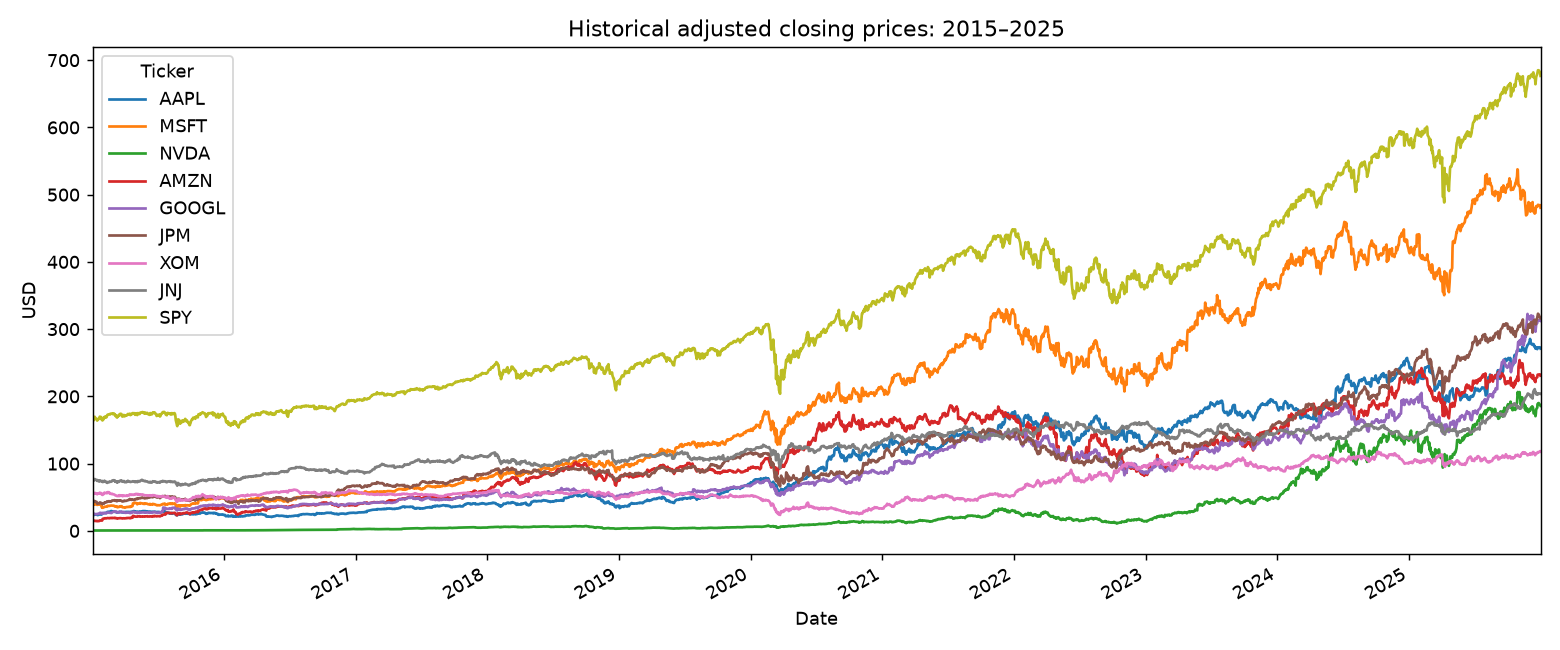

### Distribution of daily returns

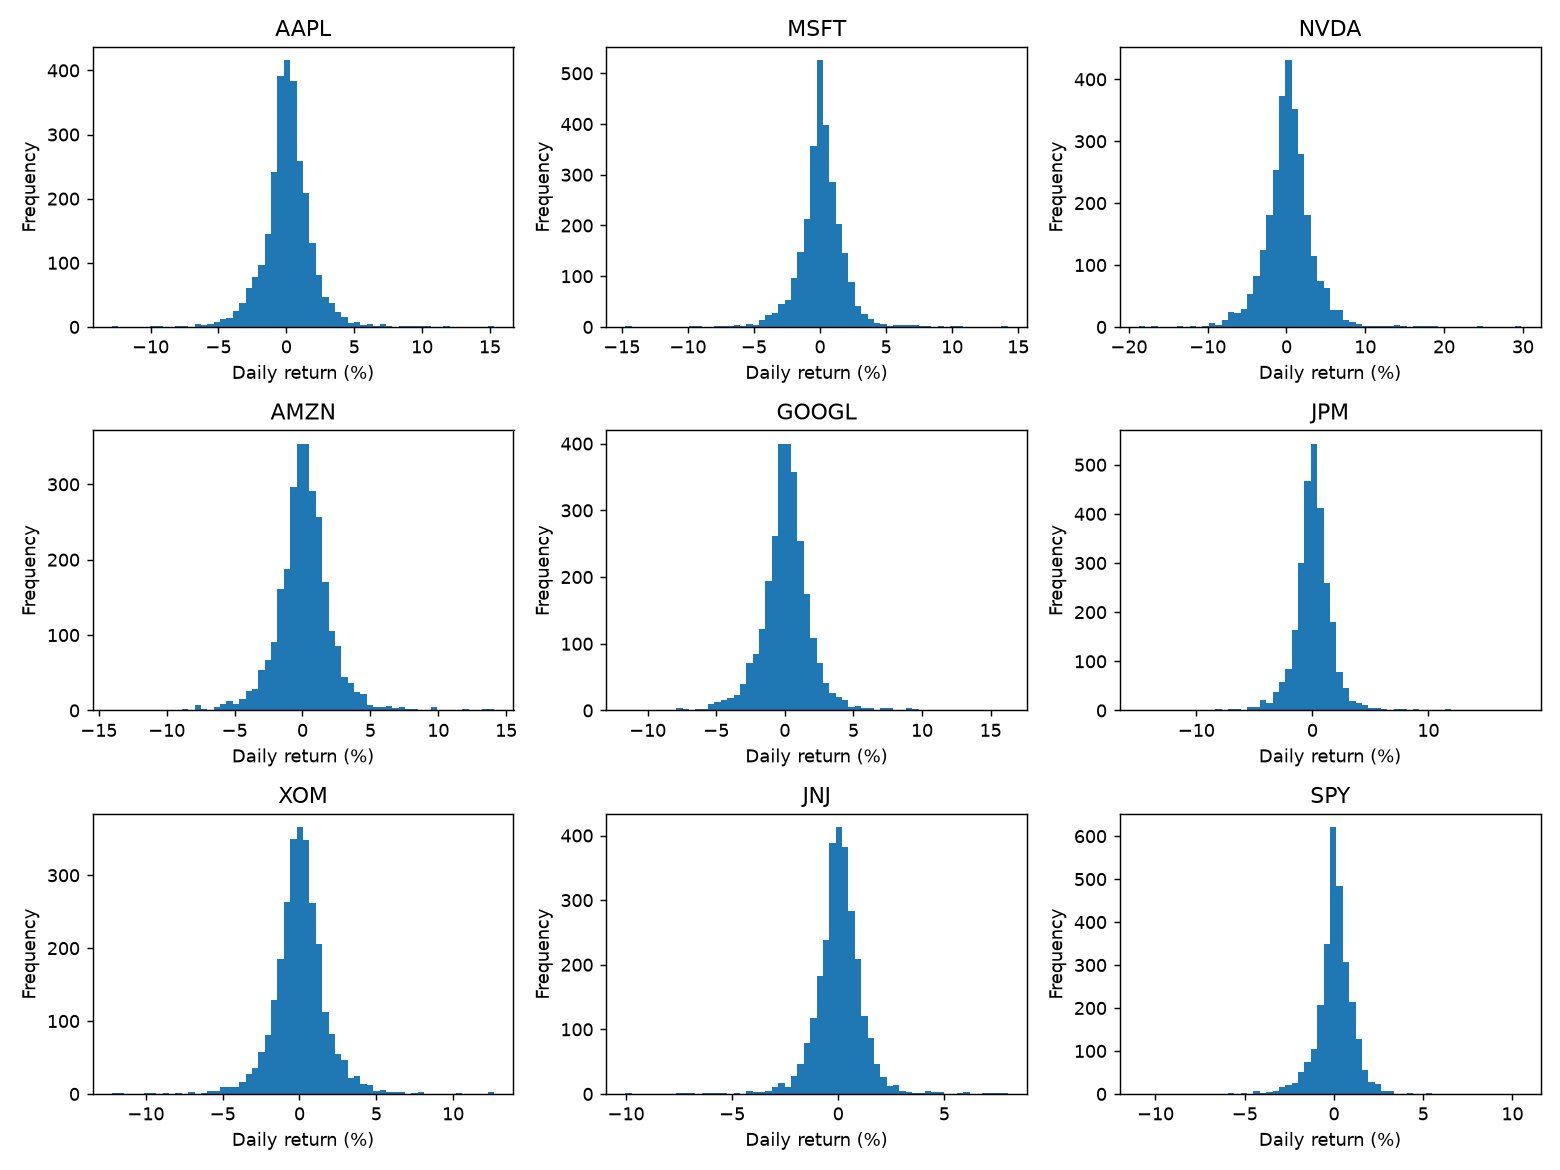

### Volatility comparison

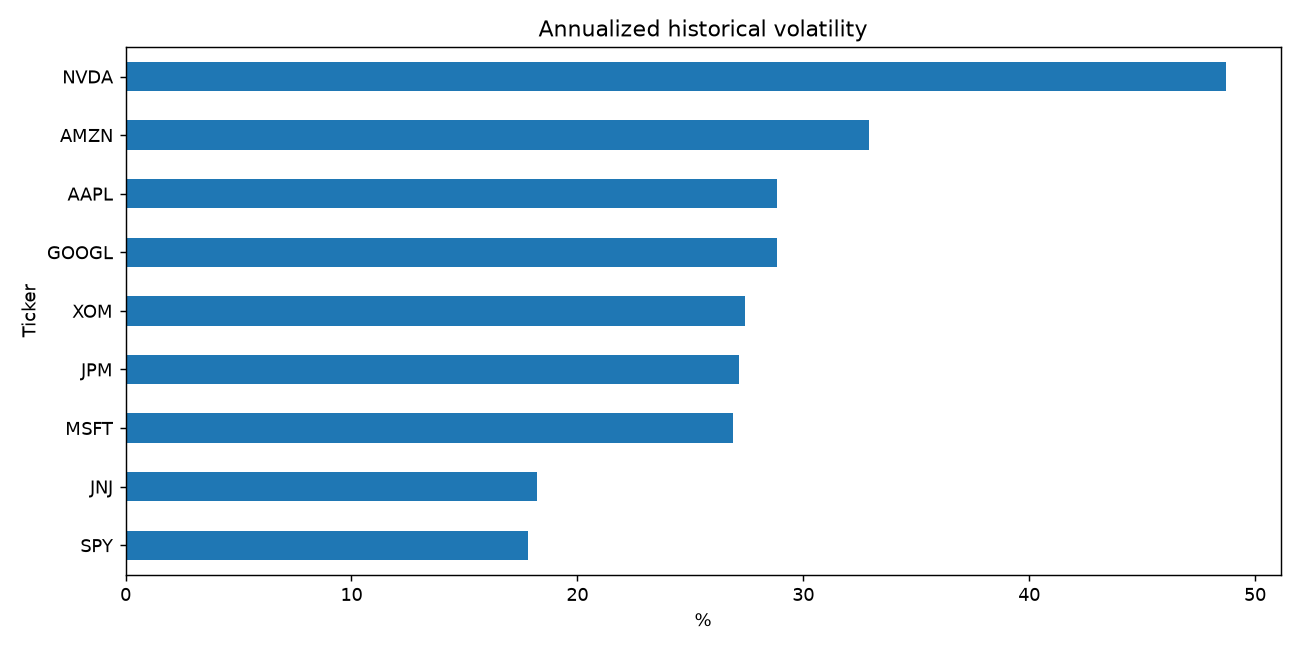

### Return correlations

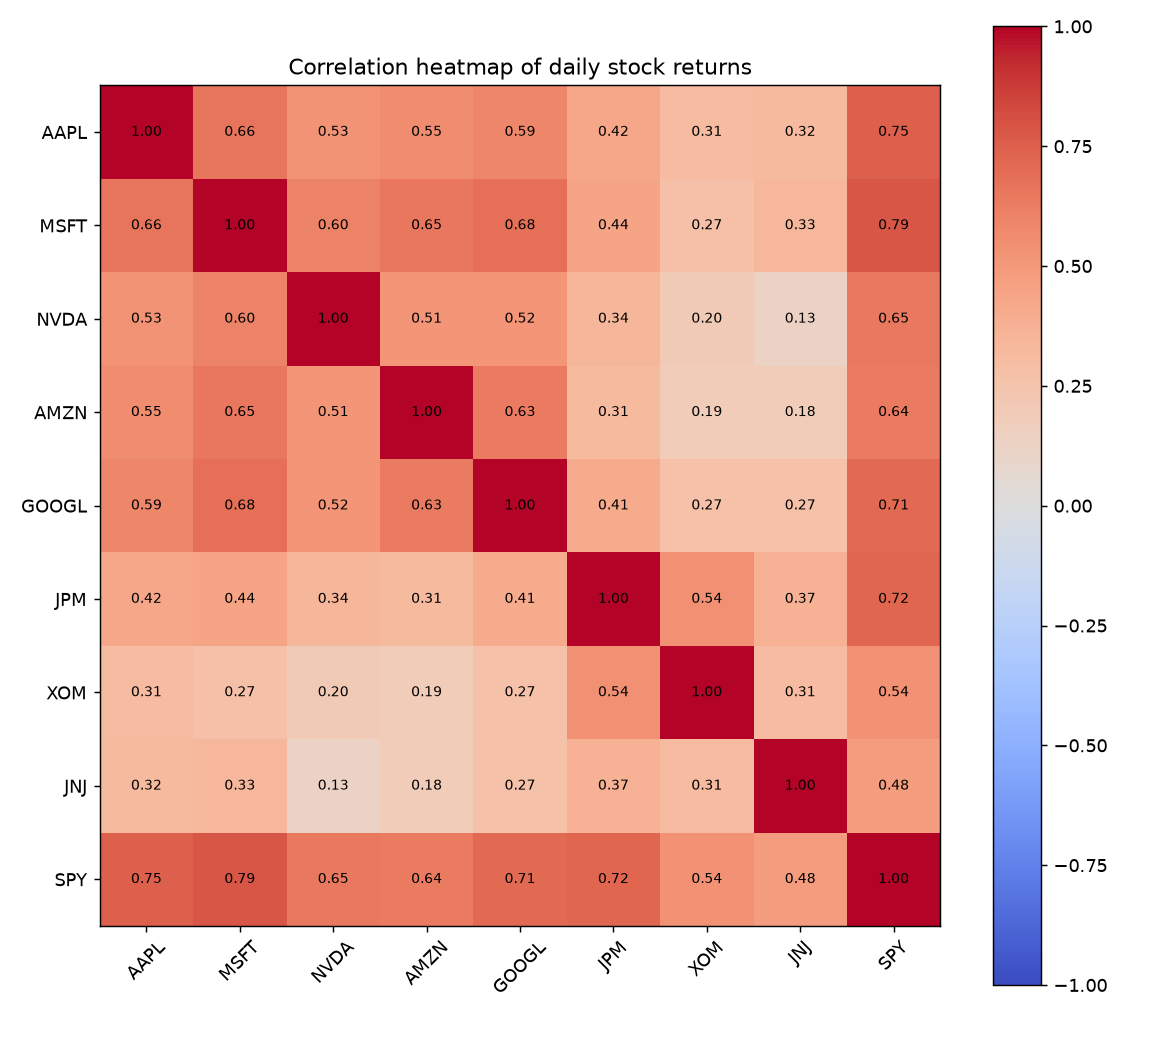

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display, Image, Markdown
eda_folder=PROJECT/'03_graficos/eda_sections'
eda_folder.mkdir(parents=True,exist_ok=True)
eda_close=raw['Close'][STOCKS+['SPY']]
eda_returns=eda_close.pct_change(fill_method=None).dropna()
eda_figures={}
fig,ax=plt.subplots(figsize=(12,5))
eda_close.plot(ax=ax)
ax.set(title='Historical adjusted closing prices: 2015–2025',ylabel='USD',xlim=(raw.index.min(),raw.index.max()))
eda_figures['Historical closing prices']=fig
fig,axes=plt.subplots(3,3,figsize=(12,9))
for ticker,ax in zip(eda_returns.columns,axes.flat):
    ax.hist(eda_returns[ticker]*100,bins=60)
    ax.set(title=ticker,xlabel='Daily return (%)',ylabel='Frequency')
eda_figures['Distribution of daily returns']=fig
fig,ax=plt.subplots(figsize=(10,5))
(eda_returns.std()*np.sqrt(252)*100).sort_values().plot.barh(ax=ax)
ax.set(title='Annualized historical volatility',xlabel='%')
eda_figures['Volatility comparison']=fig
fig,ax=plt.subplots(figsize=(9,8))
eda_corr=eda_returns.corr()
heat=ax.imshow(eda_corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(eda_corr)),eda_corr.columns,rotation=45)
ax.set_yticks(range(len(eda_corr)),eda_corr.index)
for i in range(len(eda_corr)):
    for j in range(len(eda_corr)):
        ax.text(j,i,f'{eda_corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8)
fig.colorbar(heat,ax=ax)
ax.set_title('Correlation heatmap of daily stock returns')
eda_figures['Return correlations']=fig
for name,fig in eda_figures.items():
    fig.tight_layout()
    file=eda_folder/(name.replace(' ','_')+'.png')
    fig.savefig(file,dpi=130)
    plt.close(fig)
    display(Markdown('### '+name))
    display(Image(filename=str(file)))


## 2. Feature Engineering

**12 technical features for each of 8 stocks:** returns at 1/5/10/20 sessions; price-to-MA ratios at 5/20; rolling volatility at 5/20; volume change and volume-to-MA20; RSI14; normalized MACD. This is 96 stock/feature combinations stored as a long table, not 96 pooled numeric columns. Ticker one-hot encoding identifies stocks; it is not a financial predictor.

Experiment A uses exactly 12 technical predictors. B adds VIX and three dated policy indicators. C adds three trailing event counts. The context extension deliberately adds predictors beyond the baseline 12. Economic context uses policy rates, not a complete inflation/employment dataset.

In [10]:
data,ready=engineer(raw,policy,events)
assert len(TECH)==12
assert set(data.ticker)==set(STOCKS)
assert all("spy" not in name.lower() for columns in GROUPS.values() for name in columns)
tr,val=split(data,"2023-01-01","2024-01-01")
assert tr.target_end.max()<val.date.min()
tr,test=split(data,"2024-01-01","2026-01-01")
assert tr.target_end.max()<test.date.min()
display(data.groupby("ticker")[TECH].count())
display(data.head())
print("12 predictors × 8 stocks verified. No SPY predictors or training rows.")

,return_1,return_5,return_10,return_20,ma5_ratio,ma20_ratio,volatility_5,volatility_20,volume_change,volume_ratio20,rsi14,macd_ratio
ticker,,,,,,,,,,,,
AAPL,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740
AMZN,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740
GOOGL,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740
JNJ,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740
JPM,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740
MSFT,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740
NVDA,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740
XOM,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740,2740


,date,return_1,return_5,return_10,return_20,ma5_ratio,volatility_5,ma20_ratio,volatility_20,volume_change,...,days_since_policy,tariff_count20,health_count20,war_count20,ticker,target_return,target_volatility,target_end,execution_return,execution_end
20,2015-02-02,0.012547,0.048894,0.119256,0.085063,0.024191,0.036233,0.067714,0.023813,-0.250836,...,31,0.0,0.0,0.0,AAPL,0.013171,0.109407,2015-02-09,0.018095,2015-02-10
8318,2015-02-02,0.028037,0.177001,0.253594,0.181350,0.110214,0.060182,0.192852,0.035554,-0.571099,...,31,0.0,0.0,0.0,AMZN,0.016709,0.208143,2015-02-09,0.030253,2015-02-10
11084,2015-02-02,-0.009953,-0.008422,0.042589,0.005004,0.016969,0.029401,0.031291,0.018695,-0.377597,...,31,0.0,0.0,0.0,GOOGL,-0.005486,0.151396,2015-02-09,0.004171,2015-02-10
19382,2015-02-02,0.006891,-0.013984,-0.030853,-0.035304,-0.005464,0.012303,-0.022093,0.012965,-0.157882,...,31,0.0,0.0,0.0,JNJ,-0.010414,0.227402,2015-02-09,-0.011933,2015-02-10
13850,2015-02-02,0.020044,-0.022899,-0.008225,-0.112338,0.003183,0.021733,-0.029260,0.019937,-0.246247,...,31,0.0,0.0,0.0,JPM,0.042365,0.199202,2015-02-09,0.044894,2015-02-10


12 predictors × 8 stocks verified. No SPY predictors or training rows.


## 3. Prediction Targets

### 3.1 Future Stock Return — Regression

$$R_{t,t+5}=(P_{t+5}-P_t)/P_t$$

The target uses adjusted closing prices over five trading sessions. It is kept separate from the next-session-open execution return used in portfolio simulation.

### 3.2 Future Market Risk — Classification

Compute the annualized standard deviation of the next five daily returns. High risk means exceeding the stock-specific 75th percentile estimated **only from the applicable training partition**. The threshold is recomputed within each chronological development fold.

### 3.3 Leakage prevention

Future data appear in labels only, never in predictors. Remove training rows whose target end reaches validation/test. SPY and S&P 500 remain outside training inputs and targets.

In [11]:
display(data[['date','ticker','target_return','target_volatility','target_end','execution_return']].head(16))
risk_preview_train=data[(data.date<'2023-01-01')&(data.target_end<'2023-01-01')]
risk_threshold_preview=risk_preview_train.groupby('ticker').target_volatility.quantile(.75)
display(risk_threshold_preview.rename('Training-only high-risk threshold'))

,date,ticker,target_return,target_volatility,target_end,execution_return
20,2015-02-02,AAPL,0.013171,0.109407,2015-02-09,0.018095
8318,2015-02-02,AMZN,0.016709,0.208143,2015-02-09,0.030253
11084,2015-02-02,GOOGL,-0.005486,0.151396,2015-02-09,0.004171
19382,2015-02-02,JNJ,-0.010414,0.227402,2015-02-09,-0.011933
13850,2015-02-02,JPM,0.042365,0.199202,2015-02-09,0.044894
2786,2015-02-02,MSFT,0.026163,0.104463,2015-02-09,0.026663
5552,2015-02-02,NVDA,0.038736,0.198004,2015-02-09,0.032389
16616,2015-02-02,XOM,0.029797,0.235966,2015-02-09,0.016838
21,2015-02-03,AAPL,0.032462,0.155941,2015-02-10,0.040123
8319,2015-02-03,AMZN,0.025994,0.201792,2015-02-10,0.035856


ticker
AAPL     0.318829
AMZN     0.344818
GOOGL    0.293402
JNJ      0.182349
JPM      0.271410
MSFT     0.294471
NVDA     0.510195
XOM      0.301948
Name: Training-only high-risk threshold, dtype: float64

## 4. Machine Learning Model Development

Random Forest and XGBoost are fitted for return regression and risk classification, both individually and pooled. Each algorithm has a four-configuration grid over two hyperparameters. Development uses purged training before 2023 and validation in 2023. Two earlier walk-forward windows use tuning from the preceding year only. All choices are frozen before test evaluation. Final fitting uses data before 2024; test is 2024–2025.

Regression metrics: MAE, RMSE, directional accuracy and Spearman versus zero return. Classification: accuracy, precision, recall, F1 and ROC-AUC versus majority class. Macro/event ablation uses paired errors, date aggregation, five-session bootstrap blocks and multiple-comparison correction; it is approximate and exploratory.

### 4.1 Training, tuning, chronological evaluation and baselines

This cell executes all configurations and models. Depending on Colab hardware it may take several minutes. Do not adjust choices after seeing test results. If you do, mark the next run exploratory and obtain a fresh holdout.

The shared pipeline also computes the portfolio outputs, presented separately in Part 5.

In [12]:
from research import run
result=run(PROJECT,trees=80)
display(result["tuning"])
display(result["walk"])
display(result["scores"])
display(result["significance"])
display(result["performance"])

Tuned ('A', 'pooled', 'RF', 'return') {'max_depth': 3, 'min_samples_leaf': 10}


Tuned ('A', 'pooled', 'RF', 'risk') {'max_depth': 6, 'min_samples_leaf': 30}


Tuned ('A', 'pooled', 'XGB', 'return') {'learning_rate': 0.03, 'max_depth': 2}


Tuned ('A', 'pooled', 'XGB', 'risk') {'learning_rate': 0.1, 'max_depth': 4}


Tuned ('A', 'individual', 'RF', 'return') {'max_depth': 3, 'min_samples_leaf': 10}


...

,group,architecture,algorithm,task,partition,parameters,MAE,RMSE,DirectionalAccuracy,Spearman,Accuracy,Precision,Recall,F1,ROC_AUC
0,A,pooled,RF,return,validation2023,"{""max_depth"": 3, ""min_samples_leaf"": 10}",0.029039,0.039887,0.578571,0.063906,NaN,NaN,NaN,NaN,NaN
1,A,pooled,RF,return,validation2023,"{""max_depth"": 3, ""min_samples_leaf"": 30}",0.029040,0.039864,0.579082,0.063373,NaN,NaN,NaN,NaN,NaN
2,A,pooled,RF,return,validation2023,"{""max_depth"": 6, ""min_samples_leaf"": 10}",0.029054,0.039949,0.579082,0.065924,NaN,NaN,NaN,NaN,NaN
3,A,pooled,RF,return,validation2023,"{""max_depth"": 6, ""min_samples_leaf"": 30}",0.029056,0.039955,0.580102,0.058336,NaN,NaN,NaN,NaN,NaN
4,A,pooled,RF,risk,validation2023,"{""max_depth"": 3, ""min_samples_leaf"": 10}",NaN,NaN,NaN,NaN,0.771939,0.326923,0.039627,0.070686,0.594744
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,C,individual,XGB,return,validation2023,"{""learning_rate"": 0.1, ""max_depth"": 4}",0.040656,0.055448,0.435714,-0.071451,NaN,NaN,NaN,NaN,NaN
92,C,individual,XGB,risk,validation2023,"{""learning_rate"": 0.03, ""max_depth"": 2}",NaN,NaN,NaN,NaN,0.777551,0.414634,0.039627,0.072340,0.646208
93,C,individual,XGB,risk,validation2023,"{""learning_rate"": 0.03, ""max_depth"": 4}",NaN,NaN,NaN,NaN,0.766837,0.372727,0.095571,0.152134,0.617924
94,C,individual,XGB,risk,validation2023,"{""learning_rate"": 0.1, ""max_depth"": 2}",NaN,NaN,NaN,NaN,0.768878,0.401639,0.114219,0.177858,0.651134


,group,year,algorithm,task,role,MAE,RMSE,DirectionalAccuracy,Spearman,Accuracy,Precision,Recall,F1,ROC_AUC
0,A,2021,RF,return,chronological walk-forward with earlier tuning,0.027354,0.036979,0.571356,0.087865,NaN,NaN,NaN,NaN,NaN
1,A,2021,RF,risk,chronological walk-forward with earlier tuning,NaN,NaN,NaN,NaN,0.730769,0.438202,0.074856,0.127869,0.642287
2,A,2021,XGB,return,chronological walk-forward with earlier tuning,0.027378,0.037008,0.565789,0.065023,NaN,NaN,NaN,NaN,NaN
3,A,2021,XGB,risk,chronological walk-forward with earlier tuning,NaN,NaN,NaN,NaN,0.737348,0.508621,0.113244,0.185243,0.644728
4,A,2022,RF,return,chronological walk-forward with earlier tuning,0.042689,0.056177,0.470528,-0.043936,NaN,NaN,NaN,NaN,NaN
5,A,2022,RF,risk,chronological walk-forward with earlier tuning,NaN,NaN,NaN,NaN,0.578760,0.745313,0.417323,0.535053,0.680103
6,A,2022,XGB,return,chronological walk-forward with earlier tuning,0.042839,0.056344,0.469512,-0.059258,NaN,NaN,NaN,NaN,NaN
7,A,2022,XGB,risk,chronological walk-forward with earlier tuning,NaN,NaN,NaN,NaN,0.578760,0.709333,0.465442,0.562071,0.658250
8,B,2021,RF,return,chronological walk-forward with earlier tuning,0.027410,0.037180,0.568826,0.100087,NaN,NaN,NaN,NaN,NaN
9,B,2021,RF,risk,chronological walk-forward with earlier tuning,NaN,NaN,NaN,NaN,0.733300,0.470000,0.090211,0.151369,0.641064


,group,architecture,algorithm,task,estimator,partition,MAE,RMSE,DirectionalAccuracy,Spearman,Accuracy,Precision,Recall,F1,ROC_AUC
0,A,pooled,RF,return,model,test2024_2025,0.029732,0.040779,0.580897,0.070719,NaN,NaN,NaN,NaN,NaN
1,A,pooled,RF,return,baseline,test2024_2025,0.030225,0.041176,0.414567,NaN,NaN,NaN,NaN,NaN,NaN
2,A,pooled,RF,risk,model,test2024_2025,NaN,NaN,NaN,NaN,0.798891,0.511538,0.165423,0.250000,0.636011
3,A,pooled,RF,risk,baseline,test2024_2025,NaN,NaN,NaN,NaN,0.797379,0.000000,0.000000,0.000000,0.500000
4,A,pooled,XGB,return,model,test2024_2025,0.029626,0.040590,0.581653,0.075288,NaN,NaN,NaN,NaN,NaN
5,A,pooled,XGB,return,baseline,test2024_2025,0.030225,0.041176,0.414567,NaN,NaN,NaN,NaN,NaN,NaN
6,A,pooled,XGB,risk,model,test2024_2025,NaN,NaN,NaN,NaN,0.795111,0.486486,0.201493,0.284960,0.654129
7,A,pooled,XGB,risk,baseline,test2024_2025,NaN,NaN,NaN,NaN,0.797379,0.000000,0.000000,0.000000,0.500000
8,A,individual,RF,return,model,test2024_2025,0.029839,0.040955,0.563760,0.042790,NaN,NaN,NaN,NaN,NaN
9,A,individual,RF,return,baseline,test2024_2025,0.030225,0.041176,0.414567,NaN,NaN,NaN,NaN,NaN,NaN


,architecture,algorithm,comparison,mean_MAE_improvement,ci95_low,ci95_high,p_approx,significant_bonferroni
0,pooled,RF,A→B,-3.470264e-03,-7.139431e-03,-5.987338e-04,0.115442,False
1,pooled,RF,B→C,-1.158522e-20,-4.702617e-19,4.045635e-19,0.963518,False
2,pooled,RF,A→C,-3.470264e-03,-7.409811e-03,-5.814616e-04,0.113443,False
3,pooled,XGB,A→B,-1.184462e-03,-2.560702e-03,-1.606753e-04,0.090455,False
4,pooled,XGB,B→C,-2.146660e-05,-4.594253e-05,1.237423e-06,0.078461,False
5,pooled,XGB,A→C,-1.205929e-03,-2.655600e-03,-1.641161e-04,0.073963,False
6,individual,RF,A→B,-5.389004e-05,-2.394975e-04,1.158023e-04,0.534733,False
7,individual,RF,B→C,-1.277380e-21,-1.403511e-19,1.302213e-19,0.944028,False
8,individual,RF,A→C,-5.389004e-05,-2.299428e-04,1.186403e-04,0.552224,False
9,individual,XGB,A→B,-5.707010e-05,-3.071715e-04,1.576931e-04,0.649175,False


,strategy,total_return,annualized_return,annualized_volatility,Sharpe_rf_zero,max_drawdown,final_capital
0,Equal weight,0.876230,0.371236,0.176144,1.885466,-0.195377,187623.032177
1,ML top 3,1.260597,0.505635,0.239546,1.833515,-0.265056,226059.678829
2,Risk aware ML,0.625275,0.275926,0.214796,1.245702,-0.376479,162527.506047
3,SPY,0.496773,0.224274,0.163576,1.321712,-0.187552,149677.278037


## 5. Portfolio Simulation

All strategies start at $100,000 on matching executable dates: eight-stock equal weight; ML top three forecast returns; top three among stocks predicted low risk; SPY buy-and-hold. Risk filtering may leave fewer than three or cash. The ML-only strategy chooses exactly three even when all predicted returns are negative, as required. Signals rebalance every five sessions and execute at the next open. Turnover-based fees are 10 basis points per traded dollar, including initial investment and final liquidation. SPY is the no-fee benchmark. Daily closes mark portfolios to market; final liquidation uses the open. Cash and Sharpe risk-free return are assumed zero.

Forecast selection is fixed by validation metrics; no strategy is selected using final returns.

,strategy,total_return,annualized_return,annualized_volatility,Sharpe_rf_zero,max_drawdown,final_capital
0,Equal weight,0.876230,0.371236,0.176144,1.885466,-0.195377,187623.032177
1,ML top 3,1.260597,0.505635,0.239546,1.833515,-0.265056,226059.678829
2,Risk aware ML,0.625275,0.275926,0.214796,1.245702,-0.376479,162527.506047
3,SPY,0.496773,0.224274,0.163576,1.321712,-0.187552,149677.278037


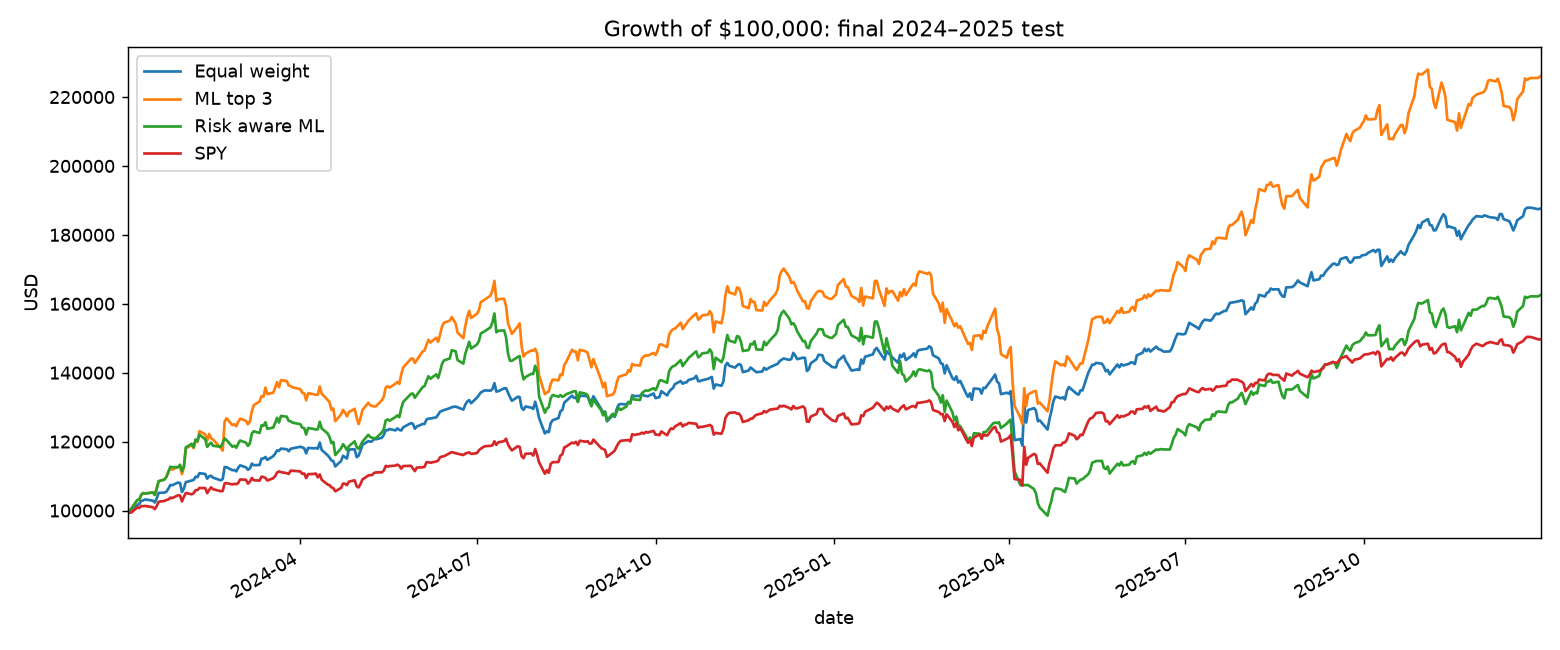

In [13]:
display(result['performance'])
display(Image(filename=str(PROJECT/'03_graficos/v2/portfolio_100000.png')))

## 6. Model Interpretation and Scientific Discussion

### 6.1 Feature importance

### feature importance return

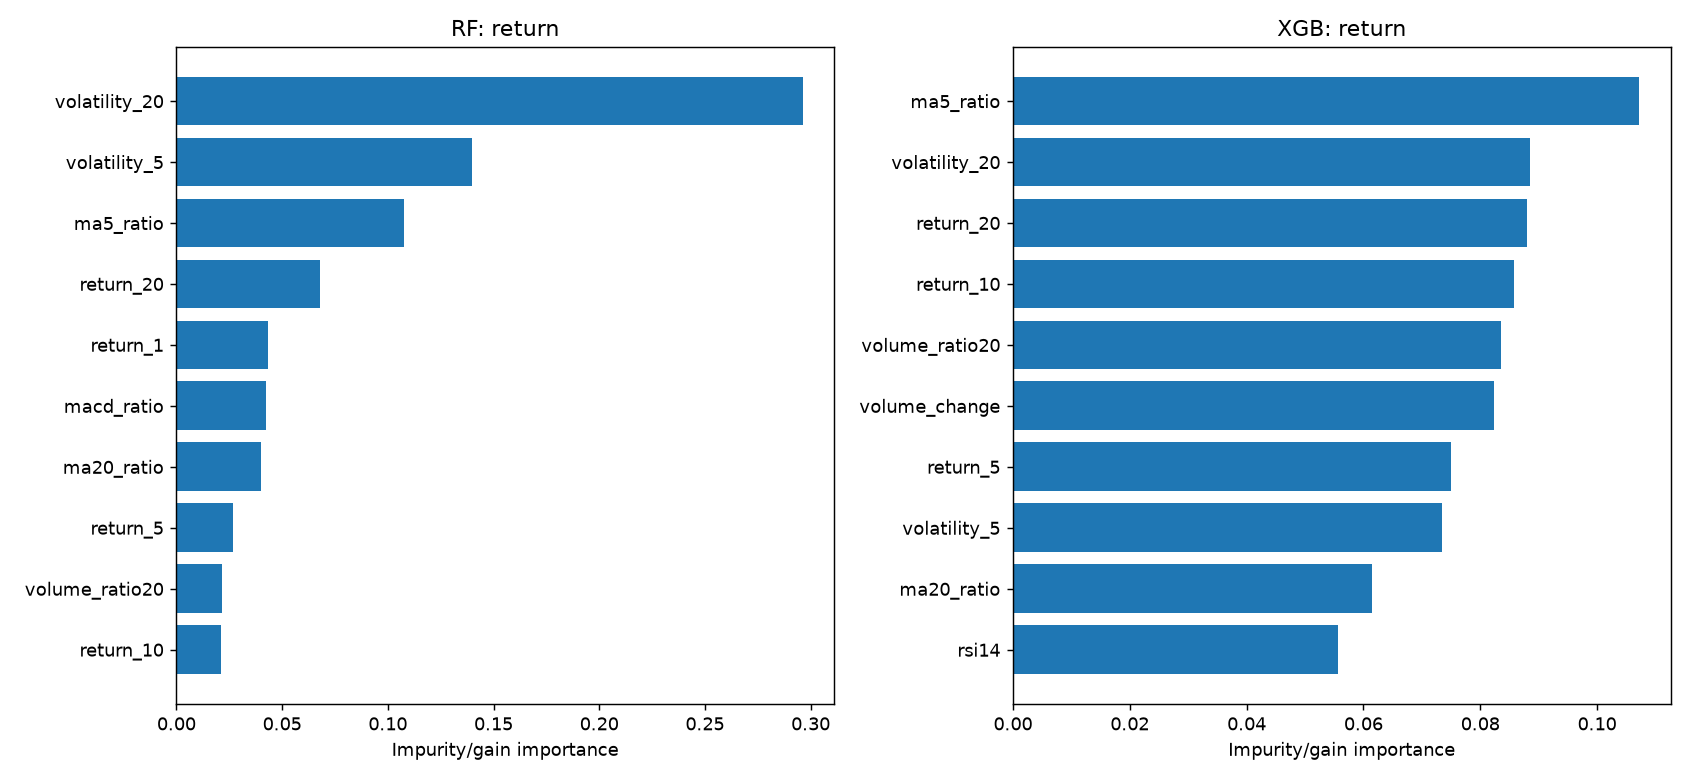

### feature importance risk

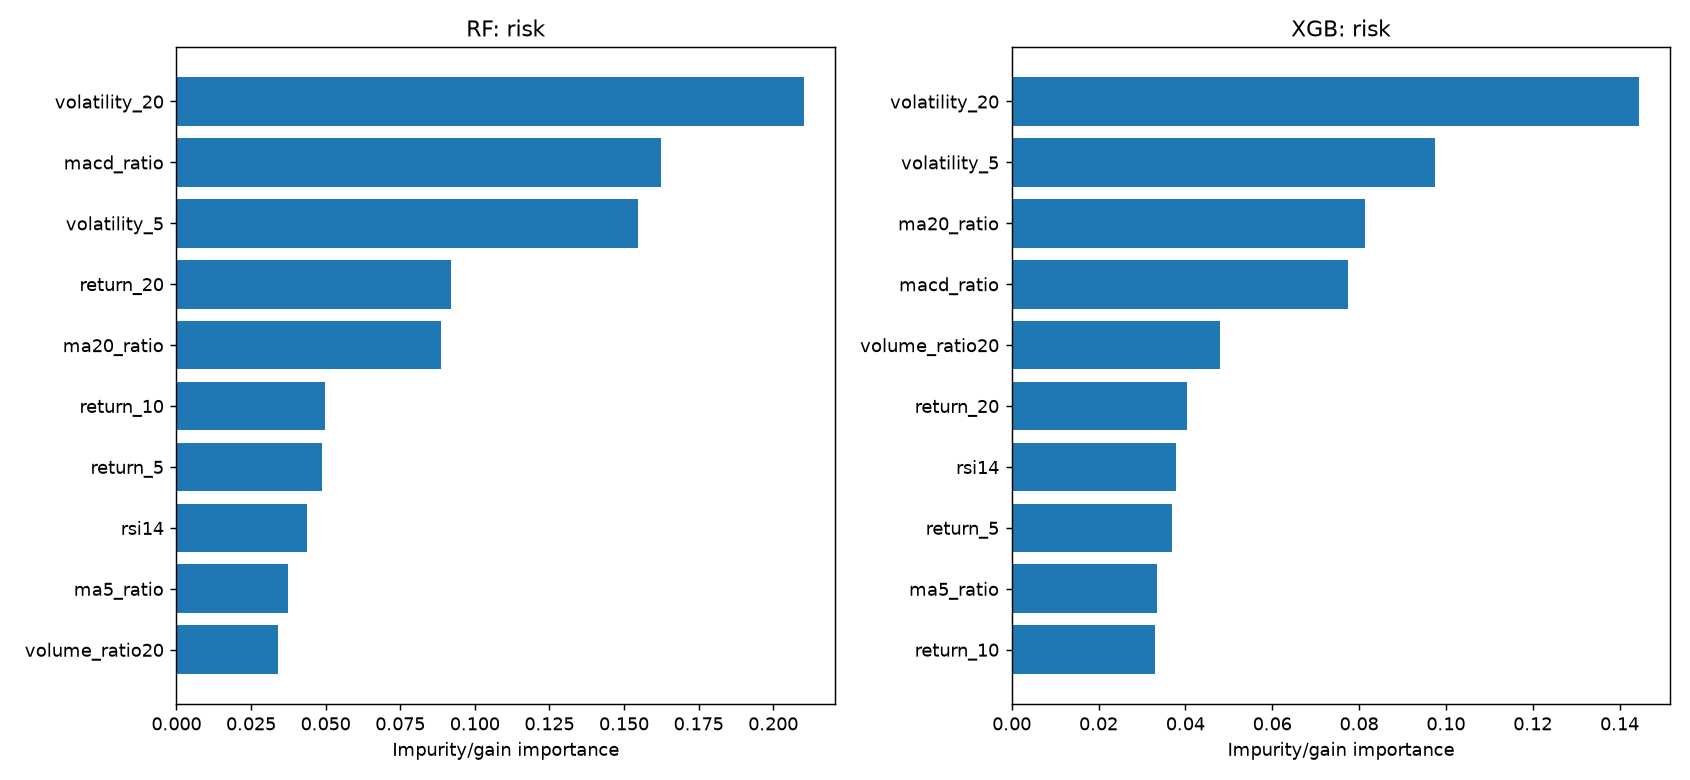

,group,architecture,algorithm,task,ticker,feature,importance
486,B,pooled,RF,return,ALL,remainder__fed_change20,0.560105
1094,C,pooled,RF,return,ALL,remainder__fed_change20,0.554890
171,A,individual,RF,return,JNJ,volatility_20,0.542994
159,A,individual,RF,return,XOM,volatility_20,0.420099
1119,C,pooled,RF,risk,ALL,remainder__vix,0.366015
127,A,individual,RF,return,AMZN,macd_ratio,0.346618
508,B,pooled,RF,risk,ALL,remainder__vix,0.337152
764,B,individual,RF,risk,GOOGL,vix,0.315689
780,B,individual,RF,risk,JPM,vix,0.304313
1439,C,individual,RF,risk,JPM,vix,0.304295


In [14]:
for image in sorted((PROJECT/'03_graficos/v2').glob('feature_importance_*.png')):
    display(Markdown('### '+image.stem.replace('_',' ')))
    display(Image(filename=str(image)))
display(result['importance'].sort_values('importance',ascending=False).head(40))

### 6.2 Interpretation of financial predictors

### RF — ten most important financial features

| Feature | Importance |

|---|---:|

| volatility_20 | 0.2962 |

| volatility_5 | 0.1398 |

| ma5_ratio | 0.1078 |

| return_20 | 0.0679 |

| return_1 | 0.0433 |

| macd_ratio | 0.0421 |

| ma20_ratio | 0.0402 |

| return_5 | 0.0267 |

| volume_ratio20 | 0.0214 |

| return_10 | 0.0212 |

### XGB — ten most important financial features

| Feature | Importance |

|---|---:|

| ma5_ratio | 0.1072 |

| volatility_20 | 0.0885 |

| return_20 | 0.0879 |

| return_10 | 0.0858 |

| volume_ratio20 | 0.0836 |

| volume_change | 0.0824 |

| return_5 | 0.0750 |

| volatility_5 | 0.0735 |

| ma20_ratio | 0.0615 |

| rsi14 | 0.0557 |



**Comparison:** both algorithms place ma5_ratio, return_20, volatility_20 among their five strongest financial predictors. RF emphasizes historical volatility; XGBoost emphasizes short-term trend and momentum, with volume also prominent. Their importance magnitudes are not directly comparable because RF uses impurity reduction and XGBoost uses gain.



**Stock consistency:** the rankings are not constant. For XGBoost individual regressors, AAPL emphasizes volatility_5, RSI14 and volatility_20, whereas JPM emphasizes volatility_5, volume_ratio20 and ma20_ratio, and NVDA emphasizes return_20, volatility_20 and ma20_ratio. The saved per-stock importance table supports these differences.



**More features:** not always beneficial. Pooled XGBoost MAE increased from 0.029626 with technical features to 0.030810 with economic context and 0.030832 with events. These optional results are exploratory. Adding predictors can add noise or regime-specific relationships.



**Interpretation limits:** importance is not a causal effect; correlated features may divide attribution. Ticker one-hot indicators identify entities and are excluded from the ten financial-feature rankings and plots. The required figures show ten financial features for both algorithms, for both return and risk tasks.

### 6.3 Critical thinking: seven required answers

### 1. Which algorithm performed better, and why?

For technical pooled return prediction, XGBoost achieved MAE **0.029626** and RMSE **0.040590**, versus Random Forest MAE **0.029732** and RMSE **0.040779**. Directional accuracy was **58.17%** versus **58.09%**, and Spearman correlation was **0.0753** versus **0.0707**. The advantage is small, so it should not be described as a decisive win.

For technical individual risk classification, XGBoost obtained F1 **0.2915** versus RF **0.2720**. Sequential boosting can fit residual nonlinear patterns differently from RF's averaging of trees; this is a plausible explanation, not a causal result established by our experiment. Differences depend on predictors, task, architecture and tuning. We did not choose new models from test results: portfolio selections remained the choices frozen on 2023 validation.

### 2. Was predicting returns harder than predicting volatility?

Raw accuracy and regression error are not comparable units. The zero-return baseline MAE was **0.030225**; pooled XGBoost reduced it by **1.98%** and achieved a modest directional accuracy of **58.17%**. The chosen individual risk classifier had accuracy **77.95%**, precision **41.76%**, recall **22.39%**, F1 **0.2915** and ROC-AUC **0.6330**. Its majority-class baseline accuracy was **79.74%** with F1 **0**.

Thus a high risk accuracy does not mean high-risk days are easy to identify: the classifier misses most high-risk cases. The experiment demonstrates weak short-horizon return information and limited high-risk detection; it does **not** establish that one task is universally easier. Comparisons must be made against the appropriate baseline.

### 3. Did pooled models outperform individual models?

With technical features, pooled RF return MAE **0.029732** was below individual RF **0.029839**; pooled XGBoost **0.029626** was below individual XGBoost **0.029806**. Pooling therefore helped return regression slightly in this configuration.

For risk, pooled RF F1 **0.2500** was below individual RF **0.2720**, and pooled XGBoost F1 **0.2850** was below individual XGBoost **0.2915**. Pooling was not uniformly better. Shared samples may aid generalization but stock-specific dynamics differ, and observations on the same date are correlated rather than eight independent market histories.

### 4. Did the ML portfolio outperform SPY?

Yes, in this historical simulation on matched executable dates within 2024–2025. ML top three returned **126.06%**, compared with **49.68%** for SPY. Equal weight returned **87.62%**, and risk-aware ML **62.53%**. All began with $100,000; ML strategies include the documented transaction costs.

The ML top-three maximum drawdown was **−26.51%**, worse than SPY's **−18.76%**, so greater return came with different risk. Selecting eight surviving stocks introduces selection/survivorship bias. A single test period cannot establish consistent future outperformance.

### 5. Did better predictive performance necessarily produce better investment returns?

No. Prediction metrics weight observations differently from a concentrated trading strategy. Portfolio returns depend on stock ranking, position sizes, trading costs and errors in the chosen stocks. MAE improvement alone does not optimize these decisions.

Here, adding the selected risk classifier reduced portfolio return from **126.06%** for ML top three to **62.53%** for risk-aware ML, and did not improve maximum drawdown (**−37.65%** for risk-aware). This shows that including a risk model did not improve this strategy, although it does not isolate predictive accuracy as the cause. We did not run a controlled portfolio comparison for every algorithm, so no broader causal conclusion is justified.

### 6. What evidence supports generalization?

Hyperparameters and model choices used only pre-2024 data; 2023 served as validation. Earlier walk-forward evaluation used hyperparameter tuning from the preceding year only. Training targets ending at or after each subsequent partition were removed. Risk thresholds were estimated separately for each stock from training rows, and algorithms were compared on identical held-out dates.

Held-out tables include zero-return and majority-class baselines. Tests verify that changing future prices cannot change earlier predictors and that modifying SPY cannot affect model predictors or targets. These checks support the evaluation's validity but do not prove universal generalization. The small MAE advantage, limited risk recall and one two-year test are weak evidence of persistent predictive skill. The test has now been inspected; future parameter changes would be exploratory and require a fresh confirmation set.

### 7. What are the limitations and improvements?

Limitations include the fixed eight-stock universe, revised adjusted prices rather than a fully point-in-time snapshot, noisy five-session targets, correlated pooled observations, small tuning grids, unstable relationships between regimes and the gap between closing-price prediction targets and next-open executable returns. The simulation assumes zero return on cash and zero risk-free rate for Sharpe, omits taxes/market impact, and cannot prove consistent future performance.

Potential improvements include a point-in-time survivorship-aware universe, additional historical market regimes for development, training-only class weighting and threshold selection, more volatility-specific predictors, and broader time-aware parameter search. They must be assessed in future experiments, not optimized against the reported test. Macroeconomic/event enhancements and the additional 70% goal are outside the current assignment-completion changes. The assignment itself does not require beating the market or attaining a minimum accuracy.

### 6.4 Detailed reproducible discussion

In [15]:
display(Markdown(result["report"]))

# Results and critical discussion



## Model comparison

On final test, lowest MAE / highest F1 for return: XGB, group A, pooled; MAE=0.0296. This is a descriptive test comparison, not a new model-selection decision.

Baseline MAE range: 0.0302–0.0302.

On final test, lowest MAE / highest F1 for risk: XGB, group A, individual; F1=0.2915. This is a descriptive test comparison, not a new model-selection decision.

Baseline F1 range: 0.0000–0.0000.



## Returns versus risk

Return regression and risk classification use different metrics and cannot be ranked by raw percentages. Compare MAE against zero-return MAE and F1/accuracy against majority-class performance. Risk persistence may aid classification while short-horizon return direction remains noisy.



## Individual versus pooled

A/RF: pooled MAE 0.0297, individual MAE 0.0298.

A/XGB: pooled MAE 0.0296, individual MAE 0.0298.

B/RF: pooled MAE 0.0332, individual MAE 0.0299.

B/XGB: pooled MAE 0.0308, individual MAE 0.0299.

C/RF: pooled MAE 0.0332, individual MAE 0.0299.

C/XGB: pooled MAE 0.0308, individual MAE 0.0298.



## Portfolio results

SPY buy-and-hold total return on matching executable dates: 49.68%.

Equal weight: total return 87.62%; annualized 37.12%; volatility 17.61%; Sharpe (cash/risk-free assumed zero) 1.89; maximum drawdown -19.54%; final capital $187,623.03.

ML top 3: total return 126.06%; annualized 50.56%; volatility 23.95%; Sharpe (cash/risk-free assumed zero) 1.83; maximum drawdown -26.51%; final capital $226,059.68.

Risk aware ML: total return 62.53%; annualized 27.59%; volatility 21.48%; Sharpe (cash/risk-free assumed zero) 1.25; maximum drawdown -37.65%; final capital $162,527.51.

SPY: total return 49.68%; annualized 22.43%; volatility 16.36%; Sharpe (cash/risk-free assumed zero) 1.32; maximum drawdown -18.76%; final capital $149,677.28.

Better predictive metrics do not necessarily yield better investment returns: ranking, exposure, errors in selected stocks, turnover and costs alter portfolio outcomes. Portfolio models were selected on 2023 validation, not final returns.



## Economic and event significance

pooled/RF A→B: paired MAE improvement -0.003470; block-bootstrap 95% CI [-0.007139, -0.000599]; approximate block sign-flip p=0.1154; positive significant improvement after 12-comparison Bonferroni: False.

pooled/RF B→C: paired MAE improvement -0.000000; block-bootstrap 95% CI [-0.000000, 0.000000]; approximate block sign-flip p=0.9635; positive significant improvement after 12-comparison Bonferroni: False.

pooled/RF A→C: paired MAE improvement -0.003470; block-bootstrap 95% CI [-0.007410, -0.000581]; approximate block sign-flip p=0.1134; positive significant improvement after 12-comparison Bonferroni: False.

pooled/XGB A→B: paired MAE improvement -0.001184; block-bootstrap 95% CI [-0.002561, -0.000161]; approximate block sign-flip p=0.0905; positive significant improvement after 12-comparison Bonferroni: False.

pooled/XGB B→C: paired MAE improvement -0.000021; block-bootstrap 95% CI [-0.000046, 0.000001]; approximate block sign-flip p=0.0785; positive significant improvement after 12-comparison Bonferroni: False.

pooled/XGB A→C: paired MAE improvement -0.001206; block-bootstrap 95% CI [-0.002656, -0.000164]; approximate block sign-flip p=0.0740; positive significant improvement after 12-comparison Bonferroni: False.

individual/RF A→B: paired MAE improvement -0.000054; block-bootstrap 95% CI [-0.000239, 0.000116]; approximate block sign-flip p=0.5347; positive significant improvement after 12-comparison Bonferroni: False.

individual/RF B→C: paired MAE improvement -0.000000; block-bootstrap 95% CI [-0.000000, 0.000000]; approximate block sign-flip p=0.9440; positive significant improvement after 12-comparison Bonferroni: False.

individual/RF A→C: paired MAE improvement -0.000054; block-bootstrap 95% CI [-0.000230, 0.000119]; approximate block sign-flip p=0.5522; positive significant improvement after 12-comparison Bonferroni: False.

individual/XGB A→B: paired MAE improvement -0.000057; block-bootstrap 95% CI [-0.000307, 0.000158]; approximate block sign-flip p=0.6492; positive significant improvement after 12-comparison Bonferroni: False.

individual/XGB B→C: paired MAE improvement 0.000043; block-bootstrap 95% CI [-0.000028, 0.000134]; approximate block sign-flip p=0.3483; positive significant improvement after 12-comparison Bonferroni: False.

individual/XGB A→C: paired MAE improvement -0.000014; block-bootstrap 95% CI [-0.000212, 0.000184]; approximate block sign-flip p=0.8976; positive significant improvement after 12-comparison Bonferroni: False.

The uncertainty analysis aggregates across stocks by date and resamples approximately five-session blocks. It is an approximate test; financial dependence may extend beyond five sessions. A predictive association does not establish a causal impact of tariffs or wars. More features can worsen generalization.



## Interpretation

RF most important predictors: remainder__volatility_20, ticker__ticker_NVDA, remainder__volatility_5, remainder__ma5_ratio, remainder__return_20.

AAPL/RF: volatility_5, volatility_20, macd_ratio.

MSFT/RF: volatility_20, macd_ratio, return_5.

NVDA/RF: volatility_20, return_20, macd_ratio.

AMZN/RF: macd_ratio, volatility_5, volatility_20.

GOOGL/RF: macd_ratio, volatility_5, return_1.

JPM/RF: return_20, macd_ratio, ma20_ratio.

XOM/RF: volatility_20, macd_ratio, return_10.

JNJ/RF: volatility_20, volatility_5, ma20_ratio.

XGB most important predictors: remainder__ma5_ratio, remainder__volatility_20, remainder__return_20, remainder__return_10, remainder__volume_ratio20.

AAPL/XGB: volatility_5, rsi14, volatility_20.

MSFT/XGB: volatility_5, volatility_20, return_5.

NVDA/XGB: return_20, volatility_20, ma20_ratio.

AMZN/XGB: macd_ratio, volatility_5, return_20.

GOOGL/XGB: ma20_ratio, return_1, return_5.

JPM/XGB: volatility_5, volume_ratio20, ma20_ratio.

XOM/XGB: rsi14, macd_ratio, volume_ratio20.

JNJ/XGB: volatility_20, volatility_5, ma20_ratio.

Importance measures are model-internal impurity/gain scores, not causal effects; correlated predictors share or distort their attribution. Ticker one-hot columns in pooled models identify entities and are not additional financial features.



## Generalization evidence and limitations

Evidence: purged chronological partitions, earlier walk-forward windows with earlier-only tuning, training-only risk thresholds, identical test dates across algorithms, and zero-return/majority/equal-weight baselines. No SPY or S&P 500 data are supplied to model fitting.

Limitations: eight selected surviving stocks; revised dividend/split-adjusted history; small and retrospectively chosen event catalogue; target dates and transaction outcomes differ; no complete point-in-time CPI/employment dataset; zero interest on cash; no borrow, tax or market-impact model; only one two-year final test. Policy rates represent economic context but do not replace inflation or employment indicators. Non-significant improvements must not be presented as proof that events help.

The test period has now been inspected: future iterations must identify themselves as exploratory and use a fresh holdout or prospective paper trading for confirmatory validation. No 2026 results are used.

The additional minimum is 70%, as updated by the user. Its metric/formula remains undefined: risk accuracy exceeds this level, while directional accuracy does not. Accuracy, F1 and investment returns must be assessed separately.



## AI assistance

AI assisted with organization, code, feature engineering and writing. Verified corrections: removed SPY returns from training features; corrected the academic target to close(t+5)/close(t)-1; separated executable next-open portfolio returns; verified feature invariance to future-price changes and purged temporal boundaries. The student should review the code, independently reproduce these checks, interpret the outputs and describe their own verification before submission.

## Final Deliverable

Submit **this single .ipynb file**, containing acquisition, EDA, features, targets, four models, tuning, metrics, baselines, three portfolios plus SPY, required figures and written conclusions. No separate report or source-code submission is required.

### Reproducibility and sources

Price snapshot: Yahoo Finance via yfinance, retrieved 12 October 2026; observations end 31 December 2025. Target end date 2026-01-01 is exclusive. Sources are linked in the policy/event tables. Policy dates are parsed only through 2025 from the Federal Reserve. Announcements are assigned a conservative next-session availability. The retrospective catalogue is incomplete and cannot establish causation.

- [yfinance download](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html)
- [Federal Reserve policy history](https://www.federalreserve.gov/monetarypolicy/openmarket.htm)
- [USTR China tariffs, 2018](https://ustr.gov/about-us/policy-offices/press-office/press-releases/2018/june/ustr-issues-tariffs-chinese-products)
- [WHO COVID timeline](https://www.who.int/news/item/29-06-2020-COVIDtimeline)
- [European Council, 24 February 2022](https://www.consilium.europa.eu/en/meetings/european-council/2022/02/24/)
- [White House tariff order, 2 April 2025](https://www.whitehouse.gov/presidential-actions/2025/04/regulating-imports-with-a-reciprocal-tariff-to-rectify-trade-practices-that-contribute-to-large-and-persistent-annual-united-states-goods-trade-deficits/)

In [16]:
import hashlib,json
manifest={name:hashlib.sha256(base64.b64decode(payload)).hexdigest() for name,payload in SNAPSHOTS.items()}
print("Input hashes:",json.dumps(manifest,indent=2))
print("Outputs:",PROJECT)

Input hashes: {
  "events.csv": "1818d3a673896d89d9ccb7da5358477f2bf636830340ca3e9af27bad9863a44b",
  "fed_policy.csv": "258bc1fd25a1e275e524e74fe01b3db61bc6effd3cf8a5a6bd858df25506f66e",
  "precios_yfinance.csv.gz": "849898ff3210b93f09553a091878da62c14012b28dd317fd6d7f5cf93a79632c"
}
Outputs: C:\Users\lariz\Documents\Codex\2026-10-12\referenced-chatgpt-conversation-this-is-an\work\notebook_organized_runtime\stock_market_generated


### Optional historical inference demo

These models were trained only before 2024. This cell forecasts all eight stocks at a held-out 2025 date, using features available then. The five-day price forecast is implied by predicted close-to-close return. No 2026 results are used. The separate Streamlit frontend adds interactive choices and a local simulated account; no broker account is connected.

In [17]:
SIGNAL_DATE=raw.index[-7]
rows=ready[ready.date.eq(SIGNAL_DATE)]
key=result["chosen"]["return"]
model_bundle=result["fitted"][key]
forecast=[]
for row in rows.itertuples():
    info=model_bundle["ALL"] if key[1]=="pooled" else model_bundle[row.ticker]
    x=rows[rows.ticker.eq(row.ticker)]
    prediction=float(info["model"].predict(x[info["columns"]])[0])
    forecast.append({"ticker":row.ticker,"signal_date":SIGNAL_DATE,"forecast_return":prediction,"implied_close_5d":float(raw["Close"].loc[SIGNAL_DATE,row.ticker])*(1+prediction)})
display(__import__("pandas").DataFrame(forecast))

,ticker,signal_date,forecast_return,implied_close_5d
0,AAPL,2025-12-22,0.004066,271.333127
1,AMZN,2025-12-22,0.004128,229.372908
2,GOOGL,2025-12-22,0.005516,310.883912
3,JNJ,2025-12-22,0.004050,204.864485
4,JPM,2025-12-22,0.004390,318.376369
5,MSFT,2025-12-22,0.004128,483.852014
6,NVDA,2025-12-22,0.012076,185.474160
7,XOM,2025-12-22,0.004750,116.376599


### Final validation checks

The following checks use direct reference formulas and controlled input perturbations, rather than merely comparing a function with itself. They verify specific corrections described in the final AI-assistance section.

In [18]:
# Independent executable checks of AI-assisted implementation
import pandas as pd
import numpy as np
from features import engineer, split, TECH, STOCKS
assert len(TECH)==12 and len(STOCKS)==8
assert data.groupby('ticker')[TECH].count().shape==(8,12)
sample=data.iloc[0]
location=raw.index.get_loc(sample.date)
reference=(raw['Close'].loc[raw.index[location+5],sample.ticker]-raw['Close'].loc[sample.date,sample.ticker])/raw['Close'].loc[sample.date,sample.ticker]
assert np.isclose(reference,sample.target_return)
changed=raw.copy()
changed.loc[:,('Close','SPY')]*=10
alternate,_=engineer(changed,policy,events)
pd.testing.assert_frame_equal(data,alternate)
boundary=raw.index[1500]
changed=raw.copy()
for ticker in STOCKS:
    changed.loc[boundary:,('Close',ticker)]*=2
_,altered_ready=engineer(changed,policy,events)
pd.testing.assert_frame_equal(ready.loc[ready.date<boundary,TECH].reset_index(drop=True),altered_ready.loc[altered_ready.date<boundary,TECH].reset_index(drop=True))
for start,end in [('2023-01-01','2024-01-01'),('2024-01-01','2026-01-01')]:
    training,held_out=split(data,start,end)
    assert training.target_end.max()<held_out.date.min()
assert raw.index.max()<pd.Timestamp('2026-01-01')
assert result['equity'].iloc[0].eq(100000).all()
print('PASS: 12×8, academic target, no SPY training, no future-price leakage, chronological purging, no 2026 observations, $100,000 initial capital.')


PASS: 12×8, academic target, no SPY training, no future-price leakage, chronological purging, no 2026 observations, $100,000 initial capital.


### AI assistance — disclosure and verified corrections

AI assistance was used for project organization, draft Python code, feature engineering, debugging, figures and explanatory writing. All reported numbers come from executed experiments with real 2015–2025 observations rather than generated claims.

**Identified and corrected AI-assisted suggestions:** an earlier implementation included SPY daily return as a training predictor, contrary to the professor's additional restriction, and used next-open execution return as the regression target. SPY was removed from predictors, and the academic target was corrected to `(Close[t+5] - Close[t]) / Close[t]`. Executable next-open returns remain separate for portfolio simulation.

**Executable verification:** the preceding cell independently computes the assignment target formula, changes SPY without changing model data, changes future prices without changing earlier technical features, checks purged date boundaries and confirms the period and starting capital. The delivered notebook records the actual results of these checks. This documents computational verification; it does not falsely claim that the student has personally performed an independent review.

**Student responsibility:** before submission, the student should rerun and understand these checks, explain the corrections in their own words, and accurately describe the verification they personally performed. AI support does not replace responsibility for interpreting the experiment and defending its conclusions.
